# ReRouter — Traffic Route Optimization System
## Continuous Evaluation 2: Model Development, Evaluation & Route Optimization

CE-1 (`01_data_preparation.ipynb`) produced a clean, encoded dataset with `speed_kmh` as the target.
This notebook builds the **machine-learning engine** of ReRouter and plugs it into a **route optimizer**.

**ReRouter pipeline**

`trip conditions` → **ML model predicts speed** → `travel time = distance ÷ speed` → **edge cost** → **Dijkstra / Q-learning** → fastest route

| Section | What we build | Syllabus topic covered |
|---|---|---|
| 1 | Data audit + peak-hour correction | EDA follow-up, feature engineering |
| 2 | Train-test split | Model evaluation: train-test split |
| 3 | Speed prediction (main model) | Linear, Multiple Linear, Polynomial regression; MAE, MSE, RMSE, R²; cross-validation; overfitting / underfitting; bias-variance |
| 4 | Congestion detection | Logistic Regression, KNN, Decision Tree, Random Forest, Naive Bayes, SVM; confusion matrix; accuracy, precision, recall, F1 |
| 5 | Zone discovery | K-Means, Hierarchical, DBSCAN, Silhouette score |
| 6 | Traffic-condition patterns | Frequent itemsets, Apriori, FP-Growth, market-basket style rules |
| 7 | Dimensionality check | Principal Component Analysis |
| 8 | Route optimization | Dijkstra + Reinforcement Learning (Q-learning) |
| 9 | Departure-time recommender | Recommendation systems |
| 10 | Responsible AI | Ethical considerations and future trends |

## 0. Setup

The same notebook runs locally (VS Code / Jupyter) and on **Google Colab**.
On Colab it installs `mlxtend` and clones the project repository automatically if the dataset is not found.

In [1]:
import sys, os, json, time, heapq, subprocess, warnings
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

try:
    import mlxtend
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mlxtend"], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, silhouette_score)
from scipy.cluster.hierarchy import linkage, dendrogram
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# ---- locate the dataset (local repo, Colab clone, or manual upload) ----
CANDIDATES = [
    Path("../data/processed/traffic_route_ml_ready.csv"),
    Path("data/processed/traffic_route_ml_ready.csv"),
    Path("ReRouter/data/processed/traffic_route_ml_ready.csv"),
    Path("traffic_route_ml_ready.csv"),
]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None and IN_COLAB:
    subprocess.run(["git", "clone", "-q", "https://github.com/ChiragDawra/ReRouter.git"], check=False)
    DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
assert DATA_PATH is not None, "Dataset not found: upload traffic_route_ml_ready.csv next to this notebook."

if DATA_PATH.parent.name == "processed":
    PROJECT_ROOT = DATA_PATH.resolve().parents[2]
else:
    PROJECT_ROOT = Path.cwd()
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
MODEL_DIR = PROJECT_ROOT / "models"
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
PEAK_HOURS = [8, 9, 10, 17, 18, 19]      # corrected in Section 1.1
CONGESTION_THRESHOLD = 25.0              # km/h, justified in Section 4.1
results = {}                             # every key number is stored here for the report

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

def reg_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse,
            "RMSE": float(np.sqrt(mse)), "R2": r2_score(y_true, y_pred)}

print("Running on Colab:", IN_COLAB)
print("Dataset:", DATA_PATH.resolve())
print("Figures will be saved to:", FIG_DIR)

Running on Colab: False
Dataset: /Users/chiragdawra/Desktop/HackSpace/ReRouter/data/processed/traffic_route_ml_ready.csv
Figures will be saved to: /Users/chiragdawra/Desktop/HackSpace/ReRouter/reports/figures


## 1. Load the CE-1 Dataset and Audit It

The ML-ready file from CE-1 has one-hot columns. The readable category labels are rebuilt from those
columns so the data can be grouped and explained.

In [2]:
df = pd.read_csv(DATA_PATH)

def from_dummies(prefix):
    cols = [c for c in df.columns if c.startswith(prefix)]
    return df[cols].idxmax(axis=1).str.replace(prefix, "", regex=False)

df["traffic"] = from_dummies("traffic_")
df["weather"] = from_dummies("weather_")
df["vehicle_type"] = from_dummies("vehicle_type_")

print("Shape:", df.shape)
df.head()

Shape: (50000, 23)


,start_lat,start_lon,end_lat,end_lon,distance_km,direct_distance_km,hour,day_of_week,is_weekend,is_peak_hour,traffic_High,traffic_Low,traffic_Medium,weather_Clear,weather_Fog,weather_Rain,vehicle_type_Bike,vehicle_type_Bus,vehicle_type_Car,speed_kmh,traffic,weather,vehicle_type
0,24.6970,67.4195,24.5436,67.7147,28.97,34.371669,12,4,0,0,0,1,0,1,0,0,0,1,0,31.498106,Low,Clear,Bus
1,24.7596,67.0422,24.3896,67.3007,8.18,48.744073,11,6,1,0,0,0,1,1,0,0,0,1,0,49.894966,Medium,Clear,Bus
2,24.1323,67.0737,23.7858,66.9700,13.45,39.943993,10,1,0,0,1,0,0,1,0,0,0,1,0,34.706390,High,Clear,Bus
3,24.2530,67.8358,24.6431,68.0697,21.47,49.418103,8,2,0,1,1,0,0,1,0,0,0,0,1,26.375888,High,Clear,Car
4,24.1442,66.7141,24.4542,66.3060,15.73,53.839844,17,0,0,1,1,0,0,0,1,0,1,0,0,22.592173,High,Fog,Bike


### 1.1 Correcting the Peak-Hour Feature

In CE-1, `is_peak_hour` was defined from a common assumption: **7–9 AM and 5–7 PM**.
The hourly EDA chart, however, shows the speed drop happens at **8, 9, 10 AM and 5, 6, 7 PM** — hour 7 is
as fast as any off-peak hour, while hour 10 is slow. The feature is therefore redefined from the data.

Speed at hour 7 : 37.93 km/h   |   hour 10 : 27.11 km/h
Correlation with speed  - old definition (7-9, 17-19) : -0.2895
Correlation with speed  - new definition (8-10, 17-19): -0.3670


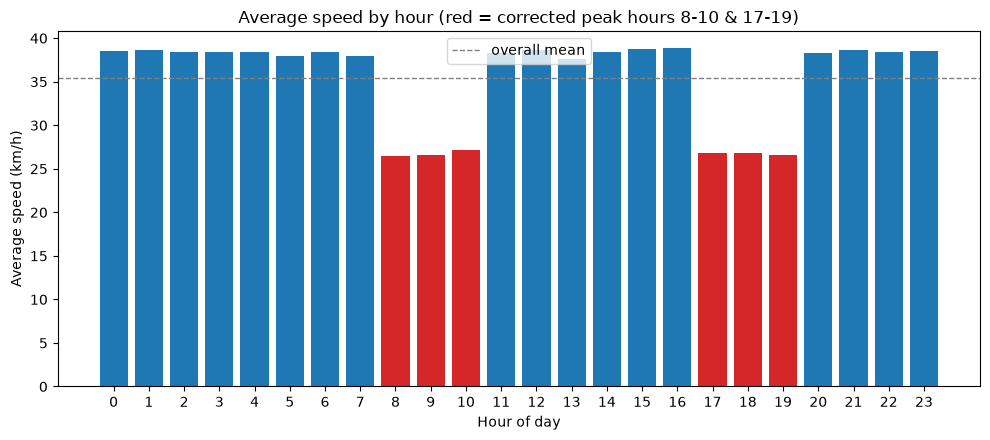

In [3]:
hourly = df.groupby("hour")["speed_kmh"].mean()
old_peak = df["hour"].isin([7, 8, 9, 17, 18, 19]).astype(int)
new_peak = df["hour"].isin(PEAK_HOURS).astype(int)

corr_old = np.corrcoef(old_peak, df["speed_kmh"])[0, 1]
corr_new = np.corrcoef(new_peak, df["speed_kmh"])[0, 1]
print(f"Speed at hour 7 : {hourly[7]:.2f} km/h   |   hour 10 : {hourly[10]:.2f} km/h")
print(f"Correlation with speed  - old definition (7-9, 17-19) : {corr_old:.4f}")
print(f"Correlation with speed  - new definition (8-10, 17-19): {corr_new:.4f}")

df["is_peak_hour"] = new_peak
results["peak_fix"] = {"corr_old": corr_old, "corr_new": corr_new,
                       "speed_h7": hourly[7], "speed_h10": hourly[10],
                       "peak_mean": df.loc[new_peak == 1, "speed_kmh"].mean(),
                       "offpeak_mean": df.loc[new_peak == 0, "speed_kmh"].mean()}

plt.figure(figsize=(10, 4.5))
colors = ["#d62728" if h in PEAK_HOURS else "#1f77b4" for h in hourly.index]
plt.bar(hourly.index, hourly.values, color=colors)
plt.axhline(df["speed_kmh"].mean(), color="gray", ls="--", lw=1, label="overall mean")
plt.title("Average speed by hour (red = corrected peak hours 8-10 & 17-19)")
plt.xlabel("Hour of day"); plt.ylabel("Average speed (km/h)"); plt.xticks(range(24)); plt.legend()
save_fig("01_hourly_speed_peak_fix"); plt.show()

### 1.2 How Speed Is Formed: Traffic × Weather

The table shows mean speed for every traffic–weather combination. The effects are **multiplicative**:
Fog cuts speed to about 70% and Rain to about 80% of the Clear-weather speed, *whatever the traffic level*.
A purely additive linear model cannot represent this exactly — this motivates polynomial (interaction) terms.

Mean speed (km/h):


weather,Clear,Rain,Fog
traffic,,,
Low,49.94,40.32,35.03
Medium,37.51,30.14,26.11
High,25.04,20.12,17.36


Speed as a fraction of Clear-weather speed:


weather,Clear,Rain,Fog
traffic,,,
Low,1.0,0.807,0.701
Medium,1.0,0.803,0.696
High,1.0,0.804,0.693


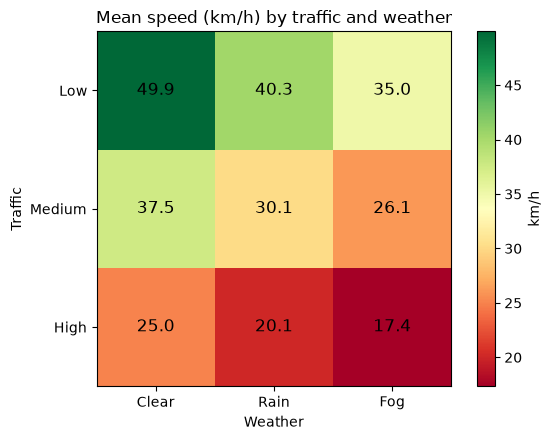

In [4]:
group_means = df.pivot_table(index="traffic", columns="weather", values="speed_kmh", aggfunc="mean")
group_means = group_means.loc[["Low", "Medium", "High"], ["Clear", "Rain", "Fog"]]
print("Mean speed (km/h):")
display(group_means.round(2))

ratio = group_means.div(group_means["Clear"], axis=0)
print("Speed as a fraction of Clear-weather speed:")
display(ratio.round(3))
results["group_means"] = group_means.round(2).to_dict()

fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(group_means.values, cmap="RdYlGn")
ax.set_xticks(range(3)); ax.set_xticklabels(group_means.columns)
ax.set_yticks(range(3)); ax.set_yticklabels(group_means.index)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{group_means.values[i, j]:.1f}", ha="center", va="center", fontsize=12)
ax.set_xlabel("Weather"); ax.set_ylabel("Traffic"); ax.set_title("Mean speed (km/h) by traffic and weather")
plt.colorbar(im, label="km/h")
save_fig("02_traffic_weather_heatmap"); plt.show()

### 1.3 Does Peak Hour Affect Speed Directly?

If peak hour slowed vehicles directly, High-traffic trips would be slower at peak than off-peak.
The table below shows they are not — peak hour changes **which traffic level occurs**, not the speed within a level.

In [5]:
print("Mean speed by traffic level and peak flag:")
display(df.pivot_table(index="traffic", columns="is_peak_hour", values="speed_kmh", aggfunc="mean").round(2))

p_traffic_given_peak = pd.crosstab(df["is_peak_hour"], df["traffic"], normalize="index")[["Low", "Medium", "High"]]
print("P(traffic level | peak flag):")
display(p_traffic_given_peak.round(3))
results["p_traffic_given_peak"] = p_traffic_given_peak.round(3).to_dict()

Mean speed by traffic level and peak flag:


is_peak_hour,0,1
traffic,,
High,23.22,23.33
Low,46.56,NaN
Medium,34.91,34.81


P(traffic level | peak flag):


traffic,Low,Medium,High
is_peak_hour,,,
0,0.5,0.300,0.200
1,0.0,0.297,0.703


### 1.4 Distance Consistency Check

A road route can never be shorter than the straight-line (Haversine) distance between its endpoints.

In [6]:
pct_impossible = (df["direct_distance_km"] > df["distance_km"]).mean() * 100
print(f"Trips where straight-line distance > recorded road distance: {pct_impossible:.1f}%")
results["pct_distance_impossible"] = pct_impossible

Trips where straight-line distance > recorded road distance: 91.4%


**Audit findings**

1. `is_peak_hour` corrected to 8–10 AM and 5–7 PM; its correlation with speed strengthens from −0.29 to −0.37.
2. Speed is driven by **traffic and weather**, combined multiplicatively.
3. Peak hour influences speed **only through traffic** — it is still valuable for *forecasting* traffic (Section 9).
4. In over 90% of trips the straight-line distance exceeds the road distance. Real roads cannot do this, so the
   dataset is **synthetic** and `distance_km` is independent of the coordinates. Coordinates are therefore used for
   *zones* (Section 5), and route distances in Section 8 are computed from coordinates.

## 2. Train-Test Split

* **80% train / 20% test** — 40,000 rows to learn from and 10,000 unseen rows for an honest final score.
* `random_state=42` makes the split reproducible.
* The split is **stratified on the congestion label** so both sets keep the same 25.5% congested share.
  The same rows are used for regression and classification so every result is comparable.
* For linear-type models one dummy column per category is dropped (reference = Low traffic, Clear weather,
  Bike) to avoid the **dummy-variable trap** (perfect multicollinearity).

In [7]:
NUMERIC = ["start_lat", "start_lon", "end_lat", "end_lon", "distance_km", "direct_distance_km",
           "hour", "day_of_week", "is_weekend", "is_peak_hour"]
DUMMIES = ["traffic_Medium", "traffic_High", "weather_Rain", "weather_Fog",
           "vehicle_type_Bus", "vehicle_type_Car"]
FEATURES_ALL = NUMERIC + DUMMIES
KEY_FEATURES = ["traffic_Medium", "traffic_High", "weather_Rain", "weather_Fog"]

df["congested"] = (df["speed_kmh"] < CONGESTION_THRESHOLD).astype(int)

X = df[FEATURES_ALL]
y_reg = df["speed_kmh"]
y_clf = df["congested"]

X_train, X_test, yr_train, yr_test, yc_train, yc_test = train_test_split(
    X, y_reg, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf)

print("Train:", X_train.shape, " Test:", X_test.shape)
print(f"Congested share  - train: {yc_train.mean():.3%}   test: {yc_test.mean():.3%}")
results["split"] = {"train": len(X_train), "test": len(X_test), "n_features": len(FEATURES_ALL),
                    "pos_train": int(yc_train.sum()), "pos_test": int(yc_test.sum()),
                    "pos_rate": float(y_clf.mean())}

Train: (40000, 16)  Test: (10000, 16)
Congested share  - train: 25.483%   test: 25.480%


## 3. Supervised Learning — Regression: Predicting Speed

**Why regression?** The route optimizer needs a *number* for every road (travel time in minutes) to add up along a
path. A class label such as "slow" cannot be summed. **Why predict speed and not time?** Speed does not depend on
segment length, so one model serves roads of any length: `time = distance ÷ predicted speed`.

### 3.1 Simple Linear Regression (one feature)

One predictor — traffic level coded 0 = Low, 1 = Medium, 2 = High: `speed = b0 + b1 × traffic_level`.

speed = 46.49 + (-11.61) x traffic_level
{'MAE': 7.8933, 'MSE': 94.1586, 'RMSE': 9.7035, 'R2': 0.5053}


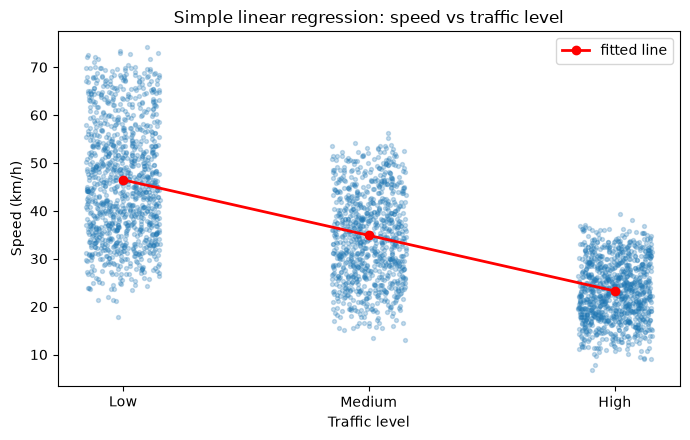

In [8]:
traffic_level = df["traffic"].map({"Low": 0, "Medium": 1, "High": 2})
tl_train, tl_test = traffic_level.loc[X_train.index].to_frame("traffic_level"), traffic_level.loc[X_test.index].to_frame("traffic_level")

slr = LinearRegression().fit(tl_train, yr_train)
slr_m = reg_metrics(yr_test, slr.predict(tl_test))
print(f"speed = {slr.intercept_:.2f} + ({slr.coef_[0]:.2f}) x traffic_level")
print({k: round(v, 4) for k, v in slr_m.items()})
results["simple_lr"] = {"b0": slr.intercept_, "b1": slr.coef_[0], **slr_m}

rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(tl_train), 3000, replace=False)
plt.figure(figsize=(7, 4.5))
plt.scatter(tl_train.values[idx, 0] + rng.uniform(-0.15, 0.15, 3000), yr_train.values[idx], alpha=0.25, s=8)
xs = np.array([[0], [1], [2]])
plt.plot(xs[:, 0], slr.predict(pd.DataFrame(xs, columns=["traffic_level"])), "r-o", lw=2, label="fitted line")
plt.xticks([0, 1, 2], ["Low", "Medium", "High"]); plt.xlabel("Traffic level"); plt.ylabel("Speed (km/h)")
plt.title("Simple linear regression: speed vs traffic level"); plt.legend()
save_fig("03_simple_linear_regression"); plt.show()

### 3.2 Multiple Linear Regression (all 16 features)

`speed = b0 + b1·x1 + b2·x2 + … + b16·x16`. Each coefficient is the change in speed for a one-unit change in that
feature, holding the others fixed.

In [9]:
mlr = LinearRegression().fit(X_train, yr_train)
coef = pd.Series(mlr.coef_, index=FEATURES_ALL).sort_values(key=np.abs, ascending=False)
print(f"Intercept: {mlr.intercept_:.3f}")
display(coef.round(4).to_frame("coefficient"))
results["mlr_coef"] = coef.round(4).to_dict()
results["mlr_intercept"] = mlr.intercept_

Intercept: 49.474


,coefficient
traffic_High,-23.1973
traffic_Medium,-11.6594
weather_Fog,-11.4611
weather_Rain,-7.4805
vehicle_type_Car,0.1074
start_lat,0.0812
is_weekend,-0.0445
end_lat,-0.0401
is_peak_hour,0.0388
start_lon,-0.0351


Only the traffic and weather coefficients are large. Location, distance, vehicle and calendar features have
coefficients close to zero — the same conclusion as the CE-1 EDA.

### 3.3 Polynomial Regression

Polynomial features add squared terms and **interaction terms** (`traffic_High × weather_Fog`), letting a linear
model represent the multiplicative effect found in Section 1.2. Features are standardised first so squared terms
stay on similar scales.

In [10]:
for d in [2, 3]:
    n_terms = PolynomialFeatures(d).fit(X_train.iloc[:5]).n_output_features_
    print(f"Degree {d}: 16 features expand to {n_terms} terms")

Degree 2: 16 features expand to 153 terms
Degree 3: 16 features expand to 969 terms


### 3.4 Tree-Based Regressors and the Final Candidate

* **Decision Tree** (depth 5) and **Random Forest** (100 trees, depth 10) capture interactions automatically.
* **Polynomial (degree 2) on the 4 key features** — traffic and weather only. Because these inputs are 0/1,
  `x² = x`, so only interaction terms are added (`interaction_only=True`), giving 4 + 6 = 10 terms.

In [11]:
reg_models = {
    "Simple Linear (traffic level)": None,
    "Multiple Linear (16 feat.)": LinearRegression(),
    "Polynomial deg 2 (16 feat.)": make_pipeline(StandardScaler(), PolynomialFeatures(2), LinearRegression()),
    "Polynomial deg 3 (16 feat.)": make_pipeline(StandardScaler(), PolynomialFeatures(3), LinearRegression()),
    "Decision Tree (depth 5)": DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest (100, depth 10)": RandomForestRegressor(n_estimators=100, max_depth=10, n_jobs=-1, random_state=RANDOM_STATE),
    "Polynomial deg 2 (4 key feat.)": make_pipeline(PolynomialFeatures(2, interaction_only=True, include_bias=False), LinearRegression()),
}

rows = []
for name, model in reg_models.items():
    t0 = time.time()
    if model is None:
        tr_pred, te_pred = slr.predict(tl_train), slr.predict(tl_test)
    else:
        cols = KEY_FEATURES if "4 key" in name else FEATURES_ALL
        model.fit(X_train[cols], yr_train)
        tr_pred, te_pred = model.predict(X_train[cols]), model.predict(X_test[cols])
    m_te = reg_metrics(yr_test, te_pred)
    rows.append({"Model": name, "Train R2": r2_score(yr_train, tr_pred), "Test R2": m_te["R2"],
                 "MAE": m_te["MAE"], "MSE": m_te["MSE"], "RMSE": m_te["RMSE"], "Time (s)": time.time() - t0})

reg_table = pd.DataFrame(rows).set_index("Model")
display(reg_table.round(4))
results["reg_table"] = reg_table.round(4).reset_index().to_dict(orient="records")

,Train R2,Test R2,MAE,MSE,RMSE,Time (s)
Model,,,,,,
Simple Linear (traffic level),0.4960,0.5053,7.8933,94.1586,9.7035,0.0020
Multiple Linear (16 feat.),0.5873,0.5929,7.2769,77.4955,8.8032,0.0113
Polynomial deg 2 (16 feat.),0.5948,0.5979,7.2329,76.5406,8.7487,0.3173
Polynomial deg 3 (16 feat.),0.6004,0.5923,7.2848,77.5950,8.8088,2.9078
Decision Tree (depth 5),0.5945,0.5981,7.2361,76.4994,8.7464,0.1169
"Random Forest (100, depth 10)",0.6209,0.5981,7.2286,76.4902,8.7459,2.3273
Polynomial deg 2 (4 key feat.),0.5935,0.5996,7.2166,76.2073,8.7297,0.0138


### 3.5 K-Fold Cross-Validation (k = 5)

One test split can be lucky or unlucky. 5-fold CV trains on 4/5 of the training data and validates on the
remaining 1/5, rotating 5 times. The **mean** estimates performance; the **standard deviation** shows stability.
Only the training set is used — the test set stays untouched until the very end.

,CV mean R2,CV std,fold scores,n_features
Model,,,,
Multiple Linear (16 feat.),0.586769,0.004660,"[0.5948, 0.5842, 0.5858, 0.5808, 0.5883]",16
Polynomial deg 2 (16 feat.),0.591328,0.004856,"[0.5996, 0.5893, 0.5895, 0.5851, 0.5932]",16
Decision Tree (depth 5),0.591626,0.004844,"[0.5997, 0.5885, 0.5903, 0.5857, 0.5939]",16
"Random Forest (100, depth 10)",0.591043,0.004791,"[0.5991, 0.588, 0.5901, 0.585, 0.593]",16
Polynomial deg 2 (4 key feat.),0.593240,0.004971,"[0.6015, 0.5903, 0.592, 0.5869, 0.5955]",4


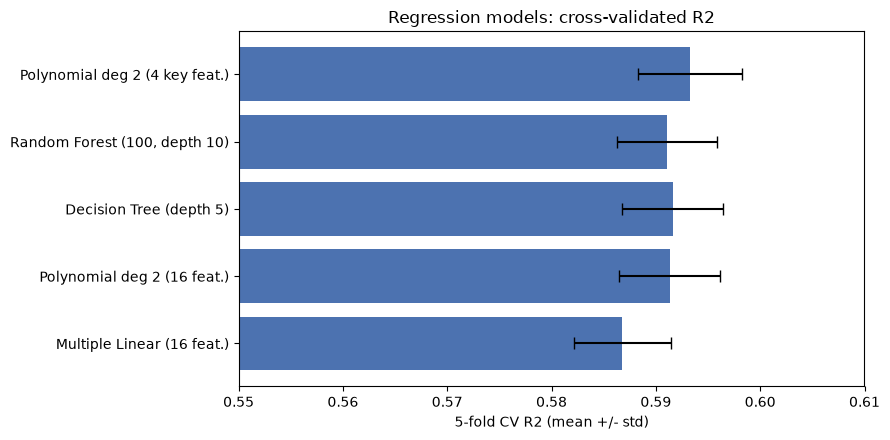

In [12]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_candidates = {
    "Multiple Linear (16 feat.)": (LinearRegression(), FEATURES_ALL),
    "Polynomial deg 2 (16 feat.)": (make_pipeline(StandardScaler(), PolynomialFeatures(2), LinearRegression()), FEATURES_ALL),
    "Decision Tree (depth 5)": (DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE), FEATURES_ALL),
    "Random Forest (100, depth 10)": (RandomForestRegressor(n_estimators=100, max_depth=10, n_jobs=-1, random_state=RANDOM_STATE), FEATURES_ALL),
    "Polynomial deg 2 (4 key feat.)": (make_pipeline(PolynomialFeatures(2, interaction_only=True, include_bias=False), LinearRegression()), KEY_FEATURES),
}
cv_rows = []
for name, (model, cols) in cv_candidates.items():
    scores = cross_val_score(model, X_train[cols], yr_train, cv=kf, scoring="r2", n_jobs=-1)
    cv_rows.append({"Model": name, "CV mean R2": scores.mean(), "CV std": scores.std(),
                    "fold scores": np.round(scores, 4).tolist(), "n_features": len(cols)})
reg_cv = pd.DataFrame(cv_rows).set_index("Model")
display(reg_cv)
results["reg_cv"] = reg_cv.reset_index().to_dict(orient="records")

plt.figure(figsize=(9, 4.5))
plt.barh(reg_cv.index, reg_cv["CV mean R2"], xerr=reg_cv["CV std"], color="#4c72b0", capsize=4)
plt.xlim(0.55, 0.61); plt.xlabel("5-fold CV R2 (mean +/- std)")
plt.title("Regression models: cross-validated R2")
save_fig("04_regression_cv"); plt.show()

### 3.6 Why Is R² About 0.59 and Not 0.95? — The Irreducible-Error Ceiling

The best possible prediction for a trip is the average speed of trips with the same conditions. Even that perfect
predictor leaves the natural trip-to-trip variation (driver behaviour, signals, etc.) unexplained.
The R² of that "perfect knowledge" predictor is the **ceiling** for any model on these features.

In [13]:
train_groups = df.loc[X_train.index].groupby(["traffic", "weather"])["speed_kmh"].mean()
oracle_pred = df.loc[X_test.index].set_index(["traffic", "weather"]).index.map(train_groups)
ceiling = r2_score(yr_test, np.asarray(oracle_pred, dtype=float))

noise_ratio = df["speed_kmh"] / df.groupby(["traffic", "weather"])["speed_kmh"].transform("mean")
print(f"R2 ceiling (group-mean predictor on test set): {ceiling:.4f}")
print(f"Trip-to-trip variation around the group mean : +/- {noise_ratio.std()*100:.1f}% (1 std)")
print(f"Total variance of speed                       : {y_reg.var():.2f}")
results["r2_ceiling"] = ceiling
results["noise_pct"] = noise_ratio.std() * 100
results["speed_var"] = y_reg.var()
results["speed_std"] = y_reg.std()

R2 ceiling (group-mean predictor on test set): 0.5996
Trip-to-trip variation around the group mean : +/- 24.0% (1 std)
Total variance of speed                       : 190.12


### 3.7 Overfitting, Underfitting and the Bias-Variance Trade-off

The Decision Tree's `max_depth` controls complexity:
* **Shallow tree** → high bias, underfits (both scores low).
* **Very deep tree** → high variance, overfits (train score near 1, test score collapses).
* The sweet spot sits in between.

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
depth,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,None
train_R2,0.3766,0.5031,0.551,0.5937,0.5945,0.5956,0.5976,0.6002,0.6036,0.6077,0.6128,0.6188,0.626,0.6348,0.6445,0.6555,0.6682,0.6831,0.6988,0.7152,1.0
test_R2,0.3878,0.5114,0.5604,0.5993,0.5981,0.5965,0.5941,0.5934,0.5903,0.5868,0.5813,0.574,0.5667,0.5564,0.5482,0.5361,0.5215,0.5061,0.4916,0.4747,0.1781


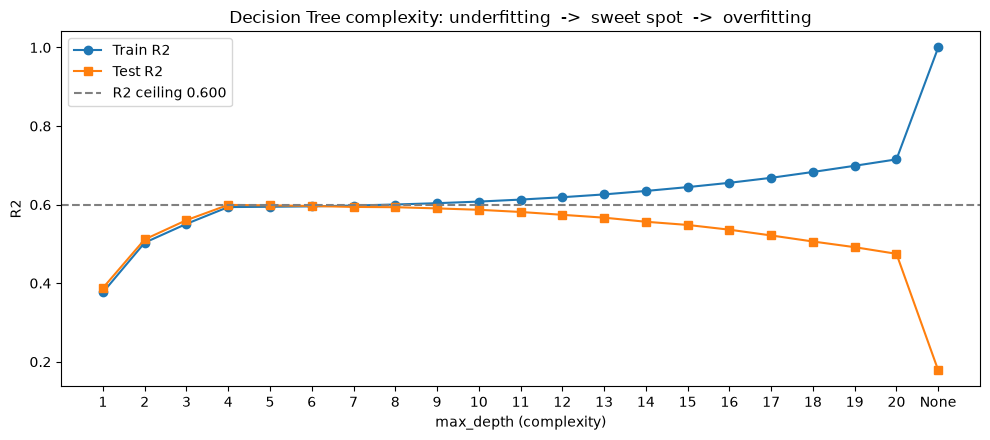

In [14]:
depths = list(range(1, 21)) + [None]
curve = []
for d in depths:
    tree = DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE).fit(X_train, yr_train)
    curve.append({"depth": "None" if d is None else d,
                  "train_R2": r2_score(yr_train, tree.predict(X_train)),
                  "test_R2": r2_score(yr_test, tree.predict(X_test))})
depth_curve = pd.DataFrame(curve)
display(depth_curve.round(4).T)
results["depth_curve"] = depth_curve.round(4).to_dict(orient="records")

plt.figure(figsize=(10, 4.5))
xs = range(len(depth_curve))
plt.plot(xs, depth_curve["train_R2"], "o-", label="Train R2")
plt.plot(xs, depth_curve["test_R2"], "s-", label="Test R2")
plt.axhline(ceiling, color="gray", ls="--", label=f"R2 ceiling {ceiling:.3f}")
plt.xticks(xs, depth_curve["depth"])
plt.xlabel("max_depth (complexity)"); plt.ylabel("R2")
plt.title("Decision Tree complexity: underfitting  ->  sweet spot  ->  overfitting")
plt.legend(); save_fig("05_bias_variance_tree_depth"); plt.show()

### 3.8 Final Regression Model

**Selection rule:** highest mean CV R²; if two models are within one standard deviation, choose the simpler one.

The polynomial model on the 4 key features has the best CV R² and is by far the simplest (10 terms), so it is the
final speed model. Its coefficients can be read directly:

Intercept (Low traffic, Clear weather): 49.897 km/h


,coefficient
traffic_Medium,-12.423
traffic_High,-24.821
weather_Rain,-9.638
weather_Fog,-14.893
traffic_Medium traffic_High,0.000
traffic_Medium weather_Rain,2.178
traffic_Medium weather_Fog,3.460
traffic_High weather_Rain,4.675
traffic_High weather_Fog,7.133
weather_Rain weather_Fog,0.000


Test metrics: {'MAE': 7.2166, 'MSE': 76.2073, 'RMSE': 8.7297, 'R2': 0.5996}
Prediction for High traffic + Fog: 17.32 km/h


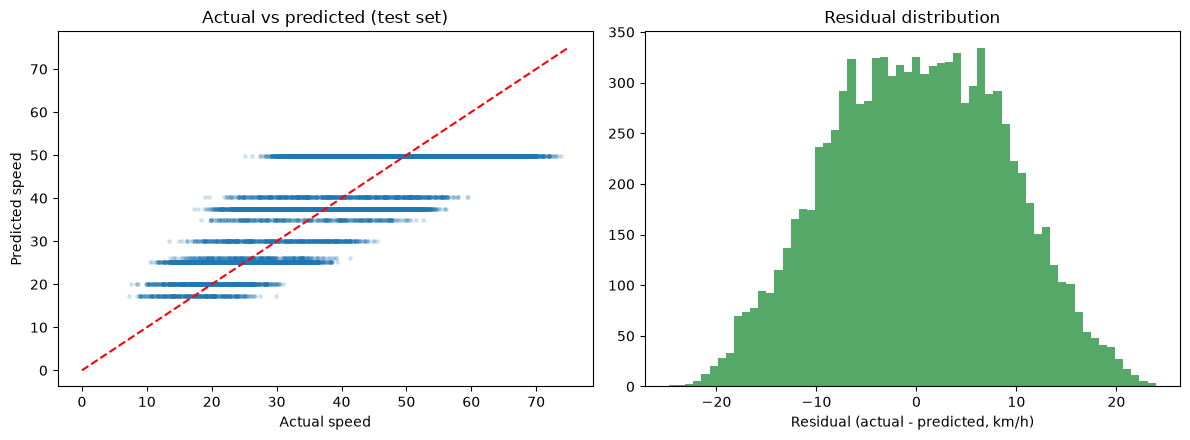

['/Users/chiragdawra/Desktop/HackSpace/ReRouter/models/speed_model_poly2.joblib']

In [15]:
final_reg = make_pipeline(PolynomialFeatures(2, interaction_only=True, include_bias=False), LinearRegression())
final_reg.fit(X_train[KEY_FEATURES], yr_train)
term_names = final_reg[0].get_feature_names_out(KEY_FEATURES)
final_coef = pd.Series(final_reg[1].coef_, index=term_names)
print(f"Intercept (Low traffic, Clear weather): {final_reg[1].intercept_:.3f} km/h")
display(final_coef.round(3).to_frame("coefficient"))

final_reg_pred = final_reg.predict(X_test[KEY_FEATURES])
final_reg_m = reg_metrics(yr_test, final_reg_pred)
print("Test metrics:", {k: round(v, 4) for k, v in final_reg_m.items()})
results["final_reg"] = {"intercept": final_reg[1].intercept_, "coef": final_coef.round(4).to_dict(), **final_reg_m}

example = pd.DataFrame([[0, 1, 0, 1]], columns=KEY_FEATURES)   # High traffic + Fog
print(f"Prediction for High traffic + Fog: {final_reg.predict(example)[0]:.2f} km/h")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(yr_test, final_reg_pred, alpha=0.15, s=6)
axes[0].plot([0, 75], [0, 75], "r--"); axes[0].set_xlabel("Actual speed"); axes[0].set_ylabel("Predicted speed")
axes[0].set_title("Actual vs predicted (test set)")
axes[1].hist(yr_test - final_reg_pred, bins=60, color="#55a868")
axes[1].set_xlabel("Residual (actual - predicted, km/h)"); axes[1].set_title("Residual distribution")
save_fig("06_final_regression_diagnostics"); plt.show()

joblib.dump(final_reg, MODEL_DIR / "speed_model_poly2.joblib")

### 3.9 Five Test Trips for Hand Calculation

The five trips below are used in the hand-calculation guide to compute MAE, MSE, RMSE and R² on paper.

In [16]:
hc_idx = X_test.index[:5]
hc = pd.DataFrame({"traffic": df.loc[hc_idx, "traffic"], "weather": df.loc[hc_idx, "weather"],
                   "actual": yr_test.loc[hc_idx].round(2),
                   "predicted": np.round(final_reg.predict(X_test.loc[hc_idx, KEY_FEATURES]), 2)})
hc["error"] = hc["actual"] - hc["predicted"]
display(hc)
results["hand_reg_rows"] = hc.reset_index(drop=True).to_dict(orient="records")

,traffic,weather,actual,predicted,error
40965,Low,Clear,58.47,49.90,8.57
28934,Low,Rain,54.01,40.26,13.75
19871,Medium,Rain,23.20,30.01,-6.81
26330,Medium,Fog,32.36,26.04,6.32
43544,Low,Clear,42.25,49.90,-7.65


## 4. Supervised Learning — Classification: Detecting Congested Trips

### 4.1 Defining the Target

`congested = 1` when speed < **25 km/h**.
* Free-flow speed (Low traffic, Clear weather) ≈ 50 km/h; congestion is commonly described as travelling at
  about half of free-flow speed → 25 km/h.
* 25 km/h is also close to the 25th percentile of speed (24.85 km/h), so about one trip in four is congested.

Use in ReRouter: a fast yes/no warning — "this road is likely congested, avoid it" — with a probability attached.

In [17]:
print(f"Free-flow mean speed (Low, Clear): {group_means.loc['Low', 'Clear']:.2f} km/h")
print(f"25th percentile of speed         : {df['speed_kmh'].quantile(0.25):.2f} km/h")
print(df["congested"].value_counts().rename({0: "not congested", 1: "congested"}))
results["clf_target"] = {"q25": df["speed_kmh"].quantile(0.25), "n_pos": int(df["congested"].sum()),
                         "n_neg": int((1 - df["congested"]).sum())}

Free-flow mean speed (Low, Clear): 49.94 km/h
25th percentile of speed         : 24.85 km/h
congested
not congested    37259
congested        12741
Name: count, dtype: int64


### 4.2 Six Classifiers

* **Scaling** (StandardScaler) is applied to distance-based or gradient-based models: Logistic Regression, KNN, SVM.
  Trees and Naive Bayes do not need it.
* **SVM** is trained on a 10,000-row stratified sample: kernel SVM cost grows roughly with the square of the number
  of rows (a full 40,000 × 40,000 kernel matrix would need about 12.8 GB of memory).

,Accuracy,Precision,Recall,F1,Train acc,Time (s)
Model,,,,,,
Logistic Regression,0.8106,0.6805,0.4839,0.5656,0.8138,0.0676
KNN (k=15),0.8128,0.6514,0.5706,0.6084,0.8423,1.0153
Decision Tree (depth 5),0.8138,0.8423,0.3312,0.4755,0.8178,0.1373
"Random Forest (200, depth 10)",0.8097,0.6750,0.4882,0.5666,0.8671,1.7911
Naive Bayes (Gaussian),0.7864,0.5642,0.7104,0.6289,0.7859,0.0181
"SVM (RBF, 10k sample)",0.8193,0.6953,0.5177,0.5935,0.8413,3.9356


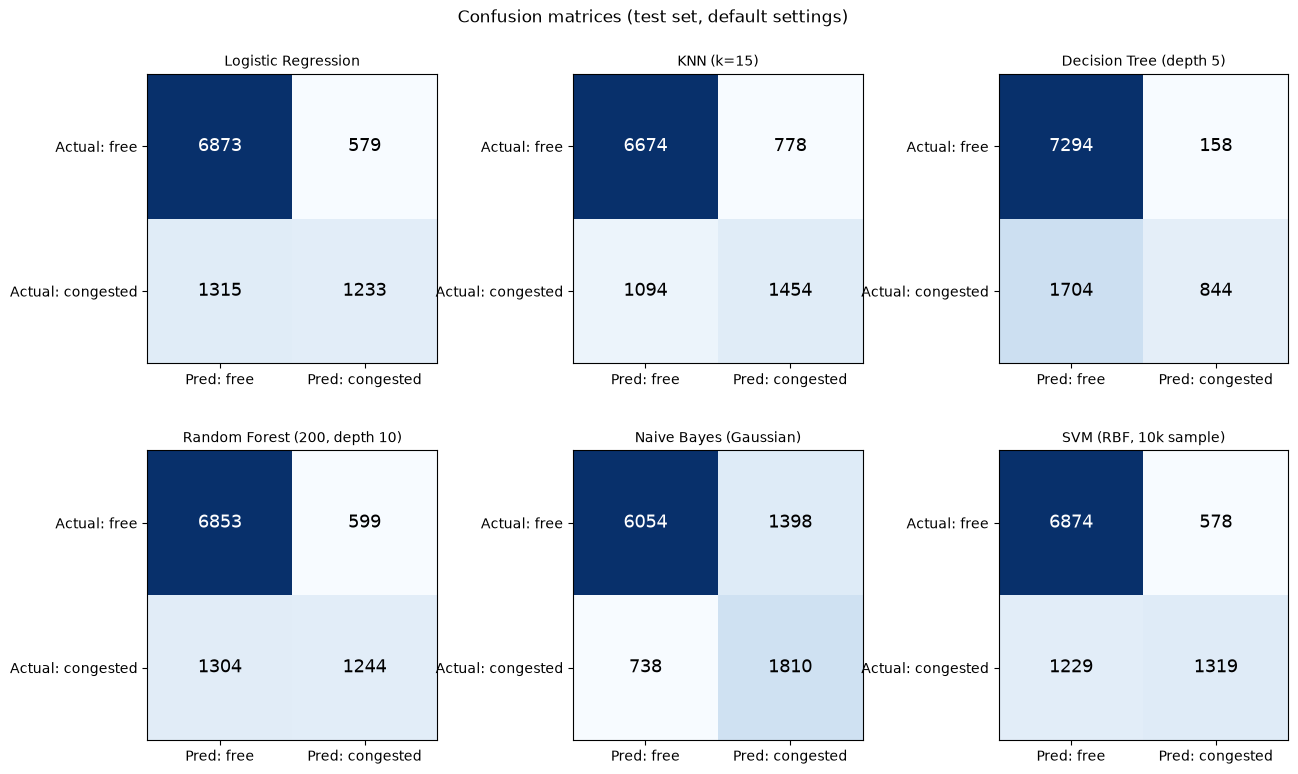

In [18]:
X_svm, _, y_svm, _ = train_test_split(X_train, yc_train, train_size=10000,
                                      random_state=RANDOM_STATE, stratify=yc_train)

def clf_models(balanced=False):
    cw = "balanced" if balanced else None
    return {
        "Logistic Regression": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight=cw)), False),
        "KNN (k=15)": (make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)), False),
        "Decision Tree (depth 5)": (DecisionTreeClassifier(max_depth=5, class_weight=cw, random_state=RANDOM_STATE), False),
        "Random Forest (200, depth 10)": (RandomForestClassifier(n_estimators=200, max_depth=10, class_weight=cw,
                                                                 n_jobs=-1, random_state=RANDOM_STATE), False),
        "Naive Bayes (Gaussian)": (GaussianNB(), False),
        "SVM (RBF, 10k sample)": (make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight=cw)), True),
    }

def evaluate_classifiers(models):
    rows, cms, fitted = [], {}, {}
    for name, (model, use_sample) in models.items():
        t0 = time.time()
        Xa, ya = (X_svm, y_svm) if use_sample else (X_train, yc_train)
        model.fit(Xa, ya)
        pred = model.predict(X_test)
        rows.append({"Model": name, "Accuracy": accuracy_score(yc_test, pred),
                     "Precision": precision_score(yc_test, pred), "Recall": recall_score(yc_test, pred),
                     "F1": f1_score(yc_test, pred), "Train acc": accuracy_score(ya, model.predict(Xa)),
                     "Time (s)": time.time() - t0})
        cms[name] = confusion_matrix(yc_test, pred)
        fitted[name] = model
    return pd.DataFrame(rows).set_index("Model"), cms, fitted

clf_table, clf_cms, _ = evaluate_classifiers(clf_models(balanced=False))
display(clf_table.round(4))
results["clf_table"] = clf_table.round(4).reset_index().to_dict(orient="records")
results["clf_cms"] = {k: v.tolist() for k, v in clf_cms.items()}

def plot_cms(cms, title, fname):
    fig, axes = plt.subplots(2, 3, figsize=(13, 8))
    for ax, (name, cm) in zip(axes.ravel(), cms.items()):
        ax.imshow(cm, cmap="Blues")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred: free", "Pred: congested"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual: free", "Actual: congested"])
        ax.set_title(name, fontsize=10)
    fig.suptitle(title); save_fig(fname); plt.show()

plot_cms(clf_cms, "Confusion matrices (test set, default settings)", "07_confusion_matrices_default")

**Observation:** accuracy is similar for all models (~0.76–0.82), but **recall differs hugely**. Because only 25% of
trips are congested, a model can score high accuracy while missing most congested trips. For routing, a missed
congestion (false negative) costs the user real time, so **recall and F1 matter more than accuracy**.

### 4.3 Choosing k for KNN

k = 1 memorises the training data (overfits); a very large k averages over too many neighbours (underfits).
k is chosen by 5-fold CV F1 on a 10,000-row sample of the training set (KNN prediction is slow on large data).

,0,1,2,3,4,5,6,7
k,1.0000,3.0000,5.0000,9.0000,15.0000,25.0000,51.0000,101.0000
train_F1,1.0000,0.7798,0.7185,0.6747,0.6462,0.6159,0.5634,0.5161
cv_F1,0.5573,0.5855,0.5841,0.5874,0.5758,0.5485,0.5203,0.4801


Best k by CV F1: 9


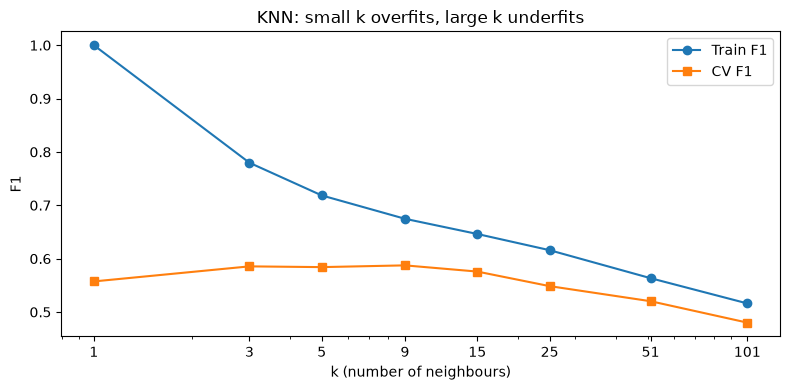

In [19]:
k_values = [1, 3, 5, 9, 15, 25, 51, 101]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
k_rows = []
for k in k_values:
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    cv_f1 = cross_val_score(knn, X_svm, y_svm, cv=skf, scoring="f1", n_jobs=-1)
    tr_f1 = f1_score(y_svm, knn.fit(X_svm, y_svm).predict(X_svm))
    k_rows.append({"k": k, "train_F1": tr_f1, "cv_F1": cv_f1.mean()})
k_curve = pd.DataFrame(k_rows)
best_k = int(k_curve.loc[k_curve["cv_F1"].idxmax(), "k"])
display(k_curve.round(4).T)
print("Best k by CV F1:", best_k)
results["knn_curve"] = k_curve.round(4).to_dict(orient="records"); results["best_k"] = best_k

plt.figure(figsize=(8, 4))
plt.semilogx(k_curve["k"], k_curve["train_F1"], "o-", label="Train F1")
plt.semilogx(k_curve["k"], k_curve["cv_F1"], "s-", label="CV F1")
plt.xticks(k_values, k_values); plt.xlabel("k (number of neighbours)"); plt.ylabel("F1")
plt.title("KNN: small k overfits, large k underfits"); plt.legend()
save_fig("08_knn_k_selection"); plt.show()

### 4.4 Handling Class Imbalance

`class_weight="balanced"` gives each congested trip about 3× the weight of a free-flowing trip
(weight = n_samples / (2 × n_class)), so the model is penalised more for missing congestion.
KNN and Naive Bayes have no class-weight option and are kept as before (KNN with the CV-selected k).

,Accuracy,Precision,Recall,F1,Train acc,Time (s)
Model,,,,,,
Logistic Regression,0.7846,0.5471,0.8976,0.6798,0.7858,0.0293
KNN (k=9),0.8050,0.6322,0.5612,0.5946,0.8494,0.8402
Decision Tree (depth 5),0.7884,0.5530,0.8842,0.6805,0.7933,0.1281
"Random Forest (200, depth 10)",0.8000,0.5717,0.8579,0.6861,0.8213,1.5146
Naive Bayes (Gaussian),0.7864,0.5642,0.7104,0.6289,0.7859,0.0154
"SVM (RBF, 10k sample)",0.7929,0.5596,0.8787,0.6838,0.8009,4.8629


Class weights used: not congested = 0.671, congested = 1.962


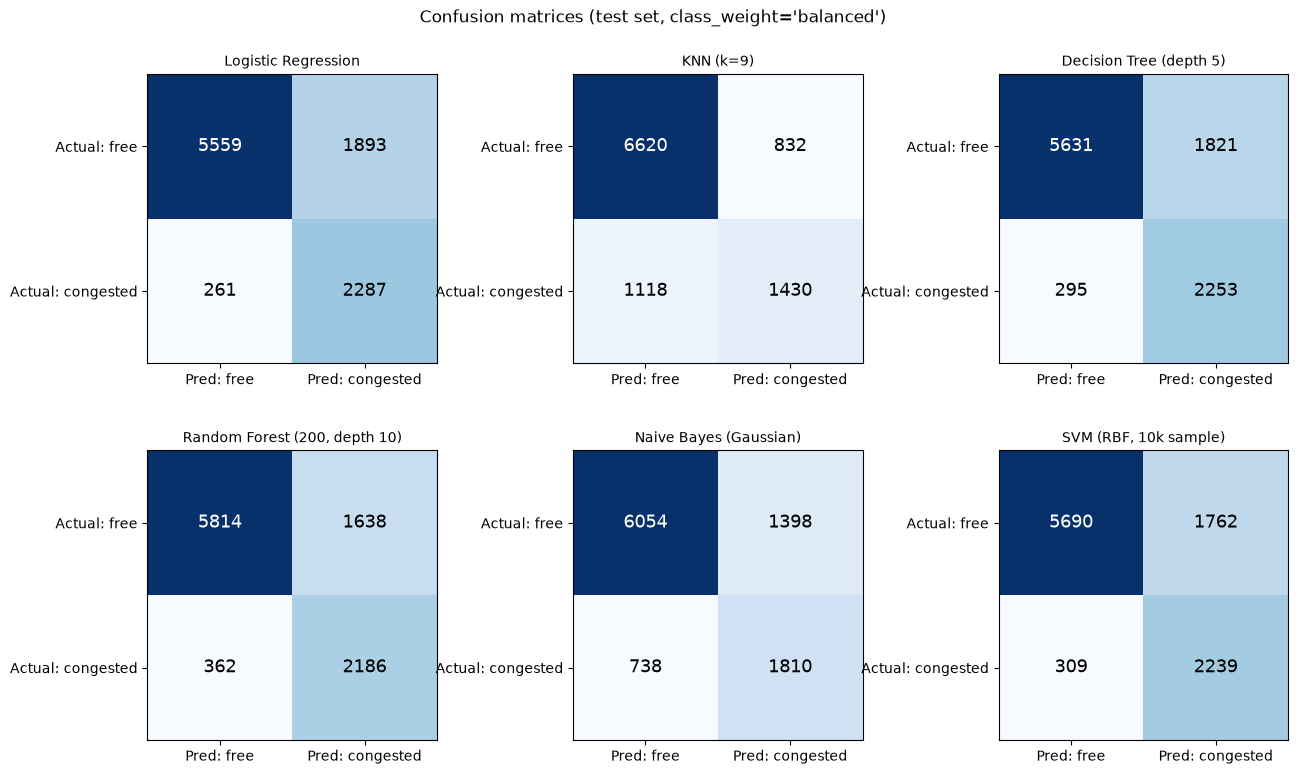

In [20]:
bal_models = clf_models(balanced=True)
bal_models["KNN (k=15)"] = (make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k)), False)
bal_models = {(f"KNN (k={best_k})" if k.startswith("KNN") else k): v for k, v in bal_models.items()}
bal_table, bal_cms, bal_fitted = evaluate_classifiers(bal_models)
display(bal_table.round(4))
results["clf_bal_table"] = bal_table.round(4).reset_index().to_dict(orient="records")
results["clf_bal_cms"] = {k: v.tolist() for k, v in bal_cms.items()}
w = len(yc_train) / (2 * np.bincount(yc_train))
print(f"Class weights used: not congested = {w[0]:.3f}, congested = {w[1]:.3f}")
results["class_weights"] = w.tolist()
plot_cms(bal_cms, "Confusion matrices (test set, class_weight='balanced')", "09_confusion_matrices_balanced")

### 4.5 Final Classifier by Stratified 5-Fold CV (F1)

**Selection rule:** highest mean CV F1; if another model is within one standard deviation, choose the simpler one
(simplicity order: Naive Bayes < Logistic Regression < KNN < Decision Tree < SVM < Random Forest).

In [21]:
simplicity = ["Naive Bayes (Gaussian)", "Logistic Regression", f"KNN (k={best_k})",
              "Decision Tree (depth 5)", "SVM (RBF, 10k sample)", "Random Forest (200, depth 10)"]
cv_clf_rows = []
for name, (model, use_sample) in bal_models.items():
    Xa, ya = (X_svm, y_svm) if use_sample else (X_train, yc_train)
    s = cross_val_score(model, Xa, ya, cv=skf, scoring="f1", n_jobs=-1)
    cv_clf_rows.append({"Model": name, "CV mean F1": s.mean(), "CV std": s.std()})
clf_cv = pd.DataFrame(cv_clf_rows).set_index("Model").sort_values("CV mean F1", ascending=False)
display(clf_cv.round(4))

best = clf_cv.index[0]
close = clf_cv[clf_cv["CV mean F1"] >= clf_cv.loc[best, "CV mean F1"] - clf_cv.loc[best, "CV std"]].index
final_clf_name = min(close, key=simplicity.index)
print("Highest CV F1          :", best)
print("Within one std of best :", list(close))
print("Final classifier       :", final_clf_name)
results["clf_cv"] = clf_cv.round(4).reset_index().to_dict(orient="records")
results["final_clf_name"] = final_clf_name

,CV mean F1,CV std
Model,,
"Random Forest (200, depth 10)",0.6844,0.0047
"SVM (RBF, 10k sample)",0.6811,0.0050
Logistic Regression,0.6807,0.0044
Decision Tree (depth 5),0.6793,0.0037
Naive Bayes (Gaussian),0.6260,0.0054
KNN (k=9),0.6024,0.0072


Highest CV F1          : Random Forest (200, depth 10)
Within one std of best : ['Random Forest (200, depth 10)', 'SVM (RBF, 10k sample)', 'Logistic Regression']
Final classifier       : Logistic Regression


In [22]:
final_clf = bal_fitted[final_clf_name]
pred = final_clf.predict(X_test)
cm = confusion_matrix(yc_test, pred)
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(classification_report(yc_test, pred, target_names=["not congested", "congested"], digits=4))
results["final_clf"] = {"TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
                        "accuracy": accuracy_score(yc_test, pred), "precision": precision_score(yc_test, pred),
                        "recall": recall_score(yc_test, pred), "f1": f1_score(yc_test, pred)}

if final_clf_name == "Logistic Regression":
    lr = final_clf[-1]
    lr_coef = pd.Series(lr.coef_[0], index=FEATURES_ALL).sort_values(key=np.abs, ascending=False)
    print("Logistic coefficients (on standardised features) and odds ratios:")
    display(pd.DataFrame({"coef": lr_coef, "odds_ratio": np.exp(lr_coef)}).round(3).head(8))
    results["final_clf"]["coef"] = lr_coef.round(4).to_dict()
    results["final_clf"]["intercept"] = float(lr.intercept_[0])

joblib.dump(final_clf, MODEL_DIR / "congestion_classifier.joblib")

TN=5559  FP=1893  FN=261  TP=2287
               precision    recall  f1-score   support

not congested     0.9552    0.7460    0.8377      7452
    congested     0.5471    0.8976    0.6798      2548

     accuracy                         0.7846     10000
    macro avg     0.7511    0.8218    0.7588     10000
 weighted avg     0.8512    0.7846    0.7975     10000

Logistic coefficients (on standardised features) and odds ratios:


,coef,odds_ratio
traffic_High,2.294,9.912
traffic_Medium,1.104,3.017
weather_Fog,0.829,2.292
weather_Rain,0.653,1.921
vehicle_type_Car,-0.020,0.981
distance_km,-0.015,0.985
start_lon,0.013,1.013
is_peak_hour,-0.010,0.990


['/Users/chiragdawra/Desktop/HackSpace/ReRouter/models/congestion_classifier.joblib']

### 4.6 Numbers for the Hand-Calculation Guide

Small, exact counts from the **training set** that make each classifier's core formula easy to verify on paper:
the Decision Tree root split (Gini and entropy), Naive Bayes with categorical counts, a 4-feature Logistic
Regression, the Random Forest bootstrap fraction, and the class weights.

In [23]:
tr = df.loc[X_train.index]
hand = {}

# Decision Tree root split on traffic_High
ct = pd.crosstab(tr["traffic_High"], tr["congested"])
hand["split_counts"] = {f"traffic_High={i}": {"free": int(ct.loc[i, 0]), "congested": int(ct.loc[i, 1])} for i in ct.index}
gini = lambda p: 1 - p ** 2 - (1 - p) ** 2
ent = lambda p: -(p * np.log2(p) + (1 - p) * np.log2(1 - p))
p_root = tr["congested"].mean()
n_left, n_right = ct.loc[0].sum(), ct.loc[1].sum()
p_left, p_right = ct.loc[0, 1] / n_left, ct.loc[1, 1] / n_right
w_l, w_r = n_left / len(tr), n_right / len(tr)
hand["gini_root"], hand["gini_left"], hand["gini_right"] = gini(p_root), gini(p_left), gini(p_right)
hand["gini_weighted"] = w_l * gini(p_left) + w_r * gini(p_right)
hand["entropy_root"], hand["entropy_weighted"] = ent(p_root), w_l * ent(p_left) + w_r * ent(p_right)
print("Root split on traffic_High (rows = traffic_High, cols = congested):"); display(ct)
print(f"Gini root {hand['gini_root']:.4f} -> weighted after split {hand['gini_weighted']:.4f}")
print(f"Entropy root {hand['entropy_root']:.4f} -> weighted after split {hand['entropy_weighted']:.4f}")

# Naive Bayes with categorical counts: P(congested | High, Fog)
nb = {}
for c in [0, 1]:
    sub = tr[tr["congested"] == c]
    nb[c] = {"n": len(sub), "prior": len(sub) / len(tr),
             "p_high": (sub["traffic"] == "High").mean(), "p_fog": (sub["weather"] == "Fog").mean()}
score = {c: nb[c]["prior"] * nb[c]["p_high"] * nb[c]["p_fog"] for c in [0, 1]}
hand["nb"] = {str(c): nb[c] for c in nb}
hand["nb_posterior"] = score[1] / (score[0] + score[1])
hand["nb_empirical"] = tr.loc[(tr["traffic"] == "High") & (tr["weather"] == "Fog"), "congested"].mean()
print(f"Naive Bayes P(congested | High, Fog) = {hand['nb_posterior']:.4f}   (observed share: {hand['nb_empirical']:.4f})")

# Logistic Regression on the 4 key features (unscaled, unweighted) -> readable coefficients
lr4 = LogisticRegression(max_iter=1000).fit(X_train[KEY_FEATURES], yc_train)
hand["lr4_intercept"] = float(lr4.intercept_[0])
hand["lr4_coef"] = dict(zip(KEY_FEATURES, np.round(lr4.coef_[0], 4).tolist()))
for name, vec in [("High+Fog", [0, 1, 0, 1]), ("Low+Clear", [0, 0, 0, 0]), ("Medium+Rain", [1, 0, 1, 0])]:
    hand[f"lr4_p_{name}"] = float(lr4.predict_proba(pd.DataFrame([vec], columns=KEY_FEATURES))[0, 1])
print("4-feature logistic regression:", hand["lr4_intercept"], hand["lr4_coef"])
print({k: round(v, 4) for k, v in hand.items() if k.startswith("lr4_p_")})

# Random Forest bootstrap and class weights
hand["oob_fraction"] = (1 - 1 / len(tr)) ** len(tr)
hand["class_weights"] = (len(tr) / (2 * tr["congested"].value_counts().sort_index())).round(4).tolist()
print(f"Fraction of rows left out of one bootstrap sample: {hand['oob_fraction']:.4f}")
print("Class weights (free, congested):", hand["class_weights"])
results["hand_clf"] = hand

Root split on traffic_High (rows = traffic_High, cols = congested):


congested,0,1
traffic_High,,
0,24654,2299
1,5153,7894


Gini root 0.3798 -> weighted after split 0.2610
Entropy root 0.8188 -> weighted after split 0.5991
Naive Bayes P(congested | High, Fog) = 0.8263   (observed share: 0.9665)
4-feature logistic regression: -4.793900461656151 {'traffic_Medium': 2.2752, 'traffic_High': 4.7677, 'weather_Rain': 1.5949, 'weather_Fog': 2.6615}
{'lr4_p_High+Fog': 0.9331, 'lr4_p_Low+Clear': 0.0082, 'lr4_p_Medium+Rain': 0.2842}
Fraction of rows left out of one bootstrap sample: 0.3679
Class weights (free, congested): [0.671, 1.9621]


## 5. Unsupervised Learning — Clustering Trip Locations into Zones

**Why cluster?** A route optimizer works on a graph of places. Clustering trip start points groups nearby
locations into **zones**; zone centres become the graph nodes used in Section 8. There is no label here — this is
unsupervised learning.

### 5.1 K-Means: Elbow Method and Silhouette Score

* **Inertia** (within-cluster sum of squared distances) always falls as k grows — look for the "elbow".
* **Silhouette** `s = (b − a) / max(a, b)` measures how well each point fits its own cluster (a) versus the nearest
  other cluster (b). Range −1 to +1; higher is better. Computed on a 5,000-point sample for speed.

,0,1,2,3,4,5,6,7,8
k,2.0000,3.0000,4.0000,5.0000,6.0000,7.0000,8.0000,9.0000,10.0000
inertia,11726.3679,7459.3685,4692.8464,3954.5428,3349.0010,2834.7582,2396.2579,2075.4000,1903.6810
silhouette,0.3528,0.3786,0.4057,0.3892,0.3706,0.3648,0.3627,0.3627,0.3658


Best k by silhouette: 4


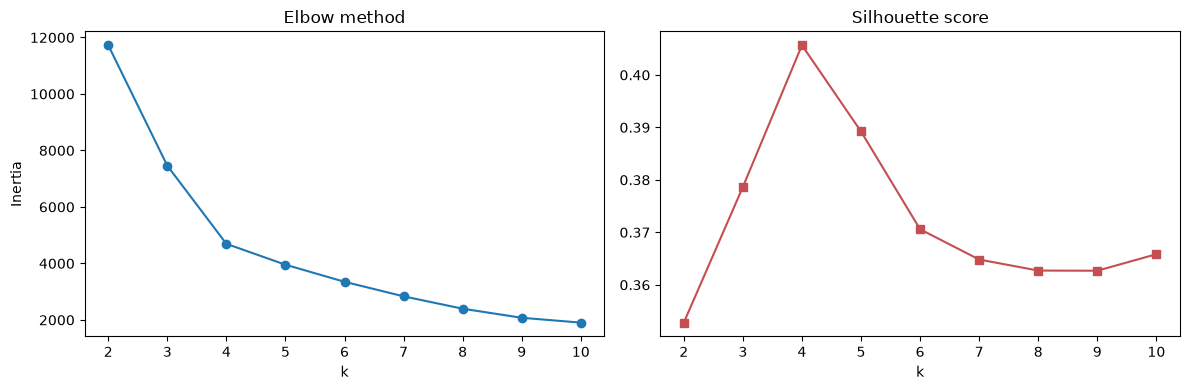

In [24]:
coords = df[["start_lat", "start_lon"]].values
sil_idx = np.random.RandomState(RANDOM_STATE).choice(len(coords), 5000, replace=False)
km_rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(coords)
    km_rows.append({"k": k, "inertia": km.inertia_,
                    "silhouette": silhouette_score(coords[sil_idx], km.labels_[sil_idx])})
km_curve = pd.DataFrame(km_rows)
display(km_curve.round(4).T)
best_k_sil = int(km_curve.loc[km_curve["silhouette"].idxmax(), "k"])
print("Best k by silhouette:", best_k_sil)
results["kmeans_curve"] = km_curve.round(4).to_dict(orient="records"); results["best_k_sil"] = best_k_sil

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(km_curve["k"], km_curve["inertia"], "o-"); axes[0].set_title("Elbow method"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
axes[1].plot(km_curve["k"], km_curve["silhouette"], "s-", color="#c44e52"); axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k")
save_fig("10_kmeans_elbow_silhouette"); plt.show()

The silhouette peaks at k = 4 but stays in a narrow band (about 0.36–0.41) for every k, because start points are
spread **uniformly** over the region — there are no natural clusters, so K-Means is *partitioning* the area.
For routing we need more than four nodes, so **k = 8 zones** is used: the silhouette is only slightly lower and the
graph becomes rich enough to have alternative routes.

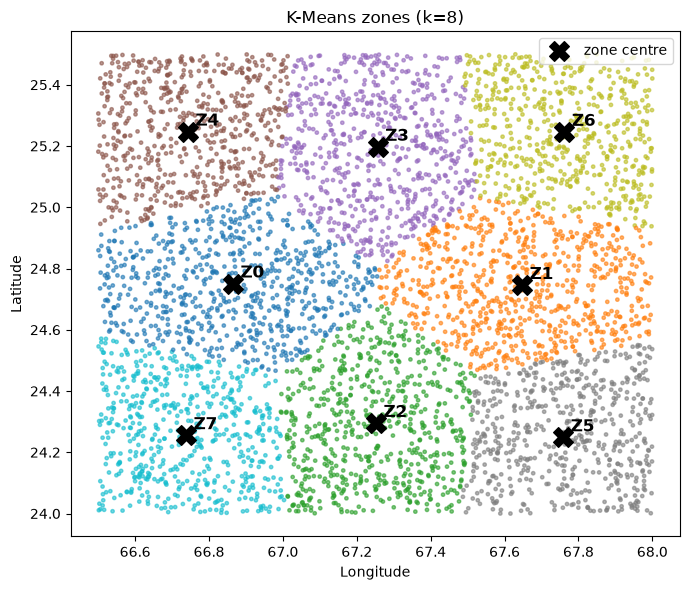

Silhouette for k=8: 0.3627


In [25]:
K_ZONES = 8
zone_km = KMeans(n_clusters=K_ZONES, n_init=10, random_state=RANDOM_STATE).fit(coords)
zone_centres = zone_km.cluster_centers_
results["zone_silhouette"] = silhouette_score(coords[sil_idx], zone_km.labels_[sil_idx])
results["zone_centres"] = np.round(zone_centres, 4).tolist()

plt.figure(figsize=(7, 6))
plt.scatter(coords[sil_idx, 1], coords[sil_idx, 0], c=zone_km.labels_[sil_idx], cmap="tab10", s=6, alpha=0.6)
plt.scatter(zone_centres[:, 1], zone_centres[:, 0], c="black", marker="X", s=200, label="zone centre")
for i, (la, lo) in enumerate(zone_centres):
    plt.text(lo + 0.02, la + 0.02, f"Z{i}", fontsize=12, weight="bold")
plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.title(f"K-Means zones (k={K_ZONES})"); plt.legend()
save_fig("11_kmeans_zones"); plt.show()
print(f"Silhouette for k={K_ZONES}: {results['zone_silhouette']:.4f}")

### 5.2 Hierarchical (Agglomerative) Clustering

Starts with every point as its own cluster and repeatedly merges the two closest clusters. The **linkage** rule
defines "closest": *single* (nearest points), *complete* (farthest points), *average*, or *Ward* (smallest increase in
variance). It needs the full pairwise-distance matrix (n² memory), so a 3,000-point sample is used.

,silhouette,largest cluster,smallest cluster
linkage,,,
ward,0.3127,517,201
complete,0.3288,542,263
average,0.3122,549,199
single,-0.5302,2976,1


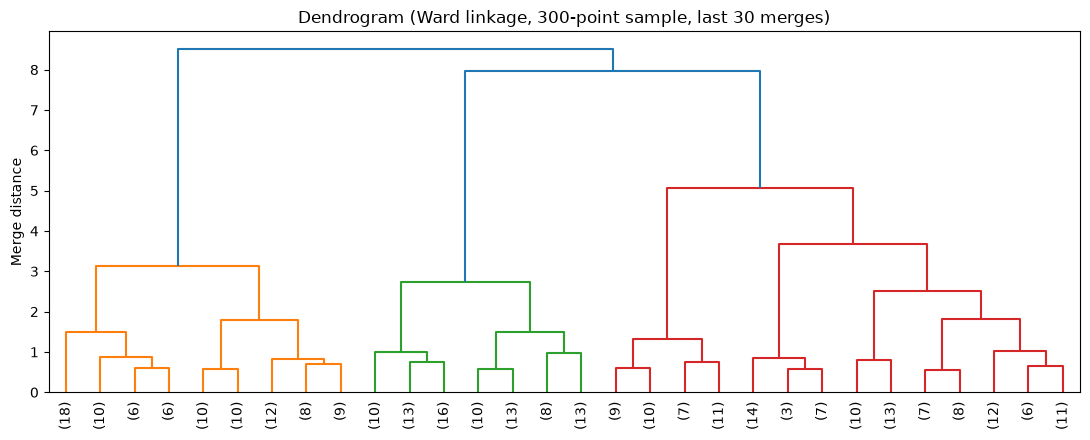

In [26]:
h_idx = np.random.RandomState(RANDOM_STATE).choice(len(coords), 3000, replace=False)
h_pts = coords[h_idx]
h_rows = []
for link in ["ward", "complete", "average", "single"]:
    ag = AgglomerativeClustering(n_clusters=K_ZONES, linkage=link).fit(h_pts)
    sizes = np.bincount(ag.labels_)
    h_rows.append({"linkage": link, "silhouette": silhouette_score(h_pts, ag.labels_),
                   "largest cluster": int(sizes.max()), "smallest cluster": int(sizes.min())})
h_table = pd.DataFrame(h_rows).set_index("linkage")
display(h_table.round(4))
results["hier_table"] = h_table.round(4).reset_index().to_dict(orient="records")

Z = linkage(h_pts[:300], method="ward")
plt.figure(figsize=(11, 4.5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90)
plt.title("Dendrogram (Ward linkage, 300-point sample, last 30 merges)"); plt.ylabel("Merge distance")
save_fig("12_dendrogram"); plt.show()

*Single* linkage suffers from **chaining** — one giant cluster plus a few single points (negative silhouette).
Ward, complete and average linkage all give balanced zones with silhouettes close to K-Means, but hierarchical
clustering needs O(n²) memory, so on all 50,000 trips **K-Means** is the practical choice; the dendrogram is still
useful to *see* how zones merge.

### 5.3 DBSCAN — Density-Based Clustering

DBSCAN groups points that have at least `min_samples` neighbours within radius `eps` (core points), and labels
isolated points as **noise** (−1). It does not need k. `eps` is read from the **k-distance plot** (distance to the
10th nearest neighbour, sorted).

,clusters,noise points,silhouette (non-noise)
eps,,,
0.02,0,3000,NaN
0.03,16,2812,0.8733
0.04,81,1246,0.4192
0.05,10,115,-0.5234
0.07,1,3,NaN


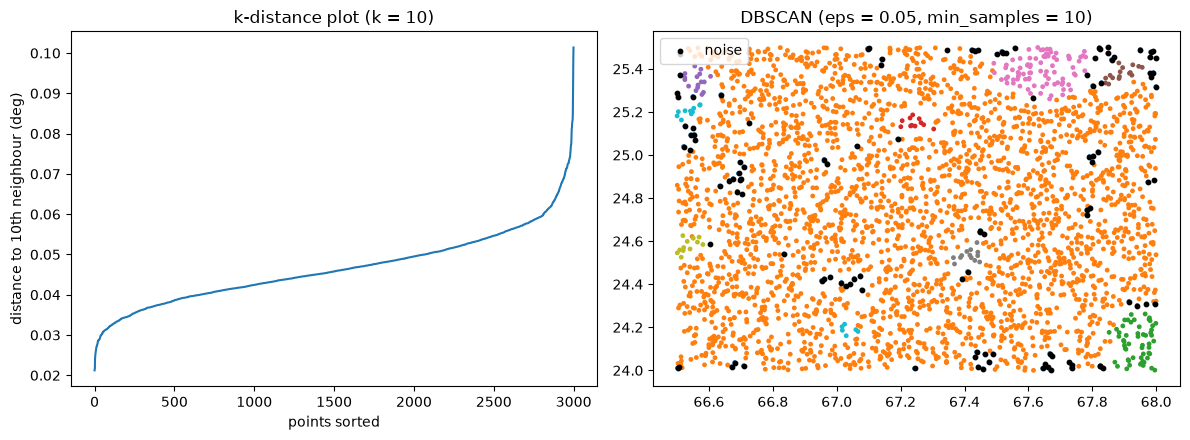

In [27]:
nn = NearestNeighbors(n_neighbors=10).fit(h_pts)
kdist = np.sort(nn.kneighbors(h_pts)[0][:, -1])
db_rows = []
for eps in [0.02, 0.03, 0.04, 0.05, 0.07]:
    lab = DBSCAN(eps=eps, min_samples=10).fit(h_pts).labels_
    n_cl = len(set(lab)) - (1 if -1 in lab else 0)
    sil = silhouette_score(h_pts[lab != -1], lab[lab != -1]) if n_cl > 1 else np.nan
    db_rows.append({"eps": eps, "clusters": n_cl, "noise points": int((lab == -1).sum()), "silhouette (non-noise)": sil})
db_table = pd.DataFrame(db_rows).set_index("eps")
display(db_table.round(4))
results["dbscan_table"] = db_table.round(4).reset_index().to_dict(orient="records")
results["kdist_median"] = float(np.median(kdist))

lab = DBSCAN(eps=0.05, min_samples=10).fit(h_pts).labels_
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(kdist); axes[0].set_title("k-distance plot (k = 10)"); axes[0].set_xlabel("points sorted"); axes[0].set_ylabel("distance to 10th neighbour (deg)")
axes[1].scatter(h_pts[:, 1], h_pts[:, 0], c=lab, cmap="tab10", s=6)
axes[1].scatter(h_pts[lab == -1, 1], h_pts[lab == -1, 0], c="black", s=10, label="noise")
axes[1].set_title("DBSCAN (eps = 0.05, min_samples = 10)"); axes[1].legend()
save_fig("13_dbscan"); plt.show()

**Comparison.** DBSCAN either labels almost everything as noise (small eps) or forms one large connected region
(large eps), because the trip density is uniform — there are no dense hotspots to find. On real city data (e.g.
taxi pick-ups around stations and malls) DBSCAN is the right tool for hotspot detection. For partitioning a
uniform area into zones, **K-Means** is the better choice.

## 6. Association Rule Learning — Which Conditions Occur Together?

Market-basket analysis finds items bought together (`{bread, butter} → {jam}`). Here each **trip is a basket** and
its conditions are the **items**: `{Traffic=High, Weather=Fog} → {Speed=Slow}`.

* **Support** = fraction of trips containing the itemset.
* **Confidence** (A → B) = support(A ∪ B) / support(A).
* **Lift** = confidence / support(B); lift > 1 means A makes B more likely than usual.

Speed bands: Slow < 25, Moderate 25–40, Fast ≥ 40 km/h. Vehicle type and weekend are left out because EDA showed
they do not affect speed.

Apriori  : 113 frequent itemsets in 0.005 s
FP-Growth: 113 frequent itemsets in 0.089 s
Same itemsets found: True


,rule,support,confidence,lift
89,"{Peak=Yes, Speed=Fast} -> {Traffic=Medium, Wea...",0.022,0.949,4.535
55,"{Traffic=High, Weather=Fog} -> {Speed=Slow}",0.032,0.965,3.786
42,"{Peak=Yes, Speed=Fast} -> {Traffic=Medium}",0.023,0.999,3.343
88,"{Peak=Yes, Speed=Fast, Weather=Clear} -> {Traf...",0.022,0.999,3.343
103,"{Peak=Yes, Traffic=High, Weather=Rain} -> {Spe...",0.029,0.812,3.186
53,"{Traffic=High, Weather=Rain} -> {Speed=Slow}",0.052,0.812,3.185
104,"{Peak=No, Traffic=High, Weather=Rain} -> {Spee...",0.024,0.811,3.184
71,"{Peak=Yes, Weather=Fog} -> {Speed=Slow}",0.021,0.807,3.165
97,"{Peak=Yes, Speed=Slow, Weather=Clear} -> {Traf...",0.061,0.931,2.850
56,"{Peak=Yes, Speed=Slow} -> {Traffic=High}",0.107,0.897,2.747


Rules that predict a Slow trip:


,rule,support,confidence,lift
55,"{Traffic=High, Weather=Fog} -> {Speed=Slow}",0.032,0.965,3.786
103,"{Peak=Yes, Traffic=High, Weather=Rain} -> {Spe...",0.029,0.812,3.186
53,"{Traffic=High, Weather=Rain} -> {Speed=Slow}",0.052,0.812,3.185
104,"{Peak=No, Traffic=High, Weather=Rain} -> {Spee...",0.024,0.811,3.184
71,"{Peak=Yes, Weather=Fog} -> {Speed=Slow}",0.021,0.807,3.165
68,"{Peak=Yes, Weather=Rain} -> {Speed=Slow}",0.033,0.656,2.573
60,"{Peak=No, Traffic=High} -> {Speed=Slow}",0.091,0.608,2.388
9,{Traffic=High} -> {Speed=Slow},0.198,0.605,2.376


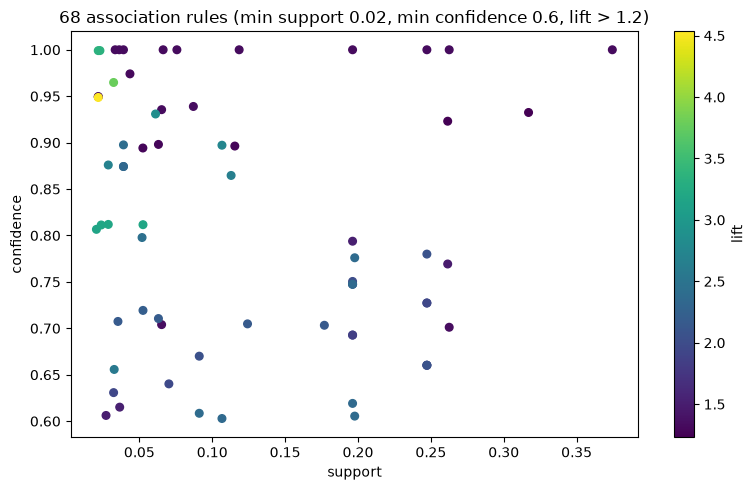

In [28]:
speed_band = pd.cut(df["speed_kmh"], bins=[0, 25, 40, np.inf], right=False, labels=["Slow", "Moderate", "Fast"])
baskets = pd.DataFrame(index=df.index)
for t in ["Low", "Medium", "High"]:
    baskets[f"Traffic={t}"] = df["traffic"] == t
for wthr in ["Clear", "Rain", "Fog"]:
    baskets[f"Weather={wthr}"] = df["weather"] == wthr
baskets["Peak=Yes"] = df["is_peak_hour"] == 1
baskets["Peak=No"] = df["is_peak_hour"] == 0
for s in ["Slow", "Moderate", "Fast"]:
    baskets[f"Speed={s}"] = speed_band == s

t0 = time.time(); freq_ap = apriori(baskets, min_support=0.02, use_colnames=True); t_ap = time.time() - t0
t0 = time.time(); freq_fp = fpgrowth(baskets, min_support=0.02, use_colnames=True); t_fp = time.time() - t0
print(f"Apriori  : {len(freq_ap)} frequent itemsets in {t_ap:.3f} s")
print(f"FP-Growth: {len(freq_fp)} frequent itemsets in {t_fp:.3f} s")
print("Same itemsets found:", set(freq_ap["itemsets"]) == set(freq_fp["itemsets"]))
results["assoc"] = {"n_itemsets": len(freq_ap), "t_apriori": t_ap, "t_fpgrowth": t_fp,
                    "support_single": baskets.mean().round(4).to_dict()}

try:
    rules = association_rules(freq_ap, num_itemsets=len(baskets), metric="confidence", min_threshold=0.6)
except TypeError:
    rules = association_rules(freq_ap, metric="confidence", min_threshold=0.6)
rules = rules[rules["lift"] > 1.2].copy()
rules["rule"] = rules["antecedents"].apply(lambda s: "{" + ", ".join(sorted(s)) + "}") + " -> " + \
                rules["consequents"].apply(lambda s: "{" + ", ".join(sorted(s)) + "}")
top_rules = rules.sort_values("lift", ascending=False)[["rule", "support", "confidence", "lift"]].head(12)
display(top_rules.round(3))

slow_rules = rules[rules["consequents"] == frozenset({"Speed=Slow"})].sort_values("confidence", ascending=False)
print("Rules that predict a Slow trip:")
display(slow_rules[["rule", "support", "confidence", "lift"]].head(8).round(3))
results["top_rules"] = top_rules.round(4).to_dict(orient="records")
results["slow_rules"] = slow_rules[["rule", "support", "confidence", "lift"]].head(8).round(4).to_dict(orient="records")

plt.figure(figsize=(8, 5))
sc = plt.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", s=30)
plt.colorbar(sc, label="lift"); plt.xlabel("support"); plt.ylabel("confidence")
plt.title(f"{len(rules)} association rules (min support 0.02, min confidence 0.6, lift > 1.2)")
save_fig("14_association_rules"); plt.show()

## 7. Dimensionality Reduction — Principal Component Analysis

PCA rotates the (standardised) features into new uncorrelated axes ordered by variance. It is useful when
features are **correlated**, because a few components then hold most of the information.

Explained variance ratio: [0.115 0.114 0.112 0.105 0.094 0.073 0.068 0.063 0.062 0.055 0.052 0.031
 0.022 0.013 0.011 0.01 ]
Components for 90% variance: 11 of 16   |   for 95%: 13
Loadings of the first 6 components (large |value| = feature dominates that component):


,PC1,PC2,PC3,PC4,PC5,PC6
start_lat,0.54,-0.44,0.09,0.01,0.02,-0.00
start_lon,0.45,0.54,-0.09,0.01,-0.00,0.00
end_lat,0.54,-0.44,0.09,0.01,0.02,-0.00
end_lon,0.45,0.54,-0.09,0.01,-0.00,-0.00
distance_km,-0.02,-0.00,0.00,0.01,-0.01,0.02
direct_distance_km,-0.00,-0.01,0.00,-0.00,0.01,-0.04
hour,0.00,-0.01,-0.01,0.20,-0.01,-0.05
day_of_week,-0.01,0.13,0.69,0.07,-0.00,0.01
is_weekend,-0.01,0.13,0.69,0.06,-0.00,0.01
is_peak_hour,-0.01,-0.01,-0.05,0.52,0.02,-0.02


,precision,recall,F1
components,,,
2,0.2606,0.5110,0.3452
4,0.6071,0.7822,0.6836
5,0.6071,0.7822,0.6836
10,0.5470,0.8108,0.6533
13,0.5471,0.8976,0.6798
16,0.5471,0.8976,0.6798


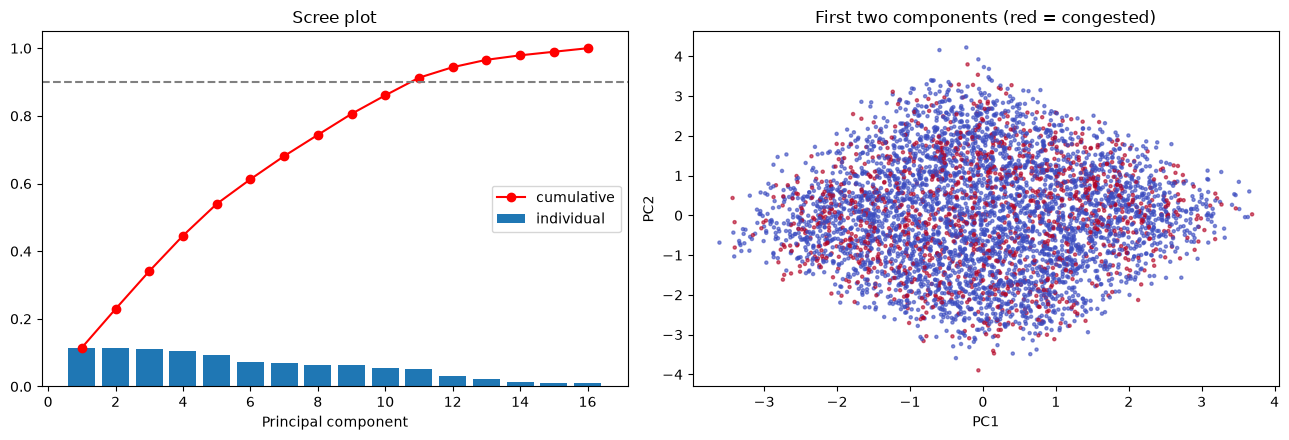

In [29]:
X_std = StandardScaler().fit_transform(X_train)
pca = PCA().fit(X_std)
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
n90, n95 = int(np.argmax(cum >= 0.90) + 1), int(np.argmax(cum >= 0.95) + 1)
print("Explained variance ratio:", np.round(evr, 3))
print(f"Components for 90% variance: {n90} of {len(evr)}   |   for 95%: {n95}")
results["pca"] = {"evr": np.round(evr, 4).tolist(), "n90": n90, "n95": n95}

loadings = pd.DataFrame(pca.components_[:6].T, index=FEATURES_ALL, columns=[f"PC{i+1}" for i in range(6)])
print("Loadings of the first 6 components (large |value| = feature dominates that component):")
display(loadings.round(2))

pca_rows = []
for nc in [2, 4, 5, 10, 13, len(FEATURES_ALL)]:
    pipe = make_pipeline(StandardScaler(), PCA(n_components=nc), LogisticRegression(max_iter=1000, class_weight="balanced"))
    pipe.fit(X_train, yc_train)
    p = pipe.predict(X_test)
    pca_rows.append({"components": nc, "precision": precision_score(yc_test, p),
                     "recall": recall_score(yc_test, p), "F1": f1_score(yc_test, p)})
pca_table = pd.DataFrame(pca_rows).set_index("components")
display(pca_table.round(4))
results["pca_f1"] = pca_table.round(4).reset_index().to_dict(orient="records")
results["pca_loadings"] = loadings.round(3).to_dict()

proj = pca.transform(X_std[:5000])[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(range(1, len(evr) + 1), evr, label="individual"); axes[0].plot(range(1, len(evr) + 1), cum, "ro-", label="cumulative")
axes[0].axhline(0.9, ls="--", color="gray"); axes[0].set_xlabel("Principal component"); axes[0].set_title("Scree plot"); axes[0].legend()
axes[1].scatter(proj[:, 0], proj[:, 1], c=yc_train.values[:5000], cmap="coolwarm", s=5, alpha=0.6)
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2"); axes[1].set_title("First two components (red = congested)")
save_fig("15_pca"); plt.show()

**Conclusion**
* Variance is spread thinly (each top component holds only ~11%), so 11 of 16 components are needed for 90%:
  most features are uncorrelated and PCA cannot compress them much.
* The loadings show *what* each component means: PC1–PC2 = location (start and end coordinates move together),
  PC3 = calendar (day of week + weekend), PC4 = traffic + peak hour, PC5 = vehicle type, PC6 = weather.
* **PCA ranks components by variance, not by usefulness.** The most predictive information (traffic, weather) sits
  in PC4 and PC6, so 2 components give almost no predictive power. With 5 components F1 looks similar, but recall drops
  (fewer congested trips caught) compared with the full feature set.
* Therefore PCA is used for **understanding and visualisation**, not in the final pipeline — the final models use
  the original, interpretable features chosen by domain reasoning and cross-validation.

## 8. Route Optimization — Dijkstra and Reinforcement Learning

### 8.1 Building the Road Graph

* **Nodes** = the 8 K-Means zone centres (Section 5).
* **Edges** = each zone connects to its 4 nearest zones (a typical junction has about four roads).
* **Edge length** = Haversine distance × 1.3. The factor 1.3 is a typical *circuity factor* (real roads are about
  20–40% longer than the straight line). This is an assumption because the dataset has no road network.
* **Live conditions** = a traffic level for every edge, drawn with a fixed seed from the traffic mix seen in the data,
  and city-wide weather.
* **Edge cost** = travel time = length ÷ (speed predicted by the final regression model) × 60 minutes.

In [30]:
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

CIRCUITY = 1.3
WEATHER_NOW = "Clear"
traffic_mix = df["traffic"].value_counts(normalize=True)[["Low", "Medium", "High"]]
rng = np.random.RandomState(RANDOM_STATE)

def predict_speed(traffic, weather):
    row = pd.DataFrame([[int(traffic == "Medium"), int(traffic == "High"),
                         int(weather == "Rain"), int(weather == "Fog")]], columns=KEY_FEATURES)
    return float(final_reg.predict(row)[0])

n = len(zone_centres)
edges = {}
for i in range(n):
    d = [haversine(*zone_centres[i], *zone_centres[j]) for j in range(n)]
    for j in np.argsort(d)[1:5]:
        a, b = sorted((i, int(j)))
        edges[(a, b)] = None
graph = {i: {} for i in range(n)}
edge_rows = []
for (a, b) in sorted(edges):
    dist = haversine(*zone_centres[a], *zone_centres[b]) * CIRCUITY
    traffic = rng.choice(traffic_mix.index, p=traffic_mix.values)
    speed = predict_speed(traffic, WEATHER_NOW)
    t_min = dist / speed * 60
    graph[a][b] = graph[b][a] = {"dist": dist, "time": t_min, "traffic": traffic, "speed": speed}
    edge_rows.append({"edge": f"Z{a}-Z{b}", "km": dist, "traffic": traffic, "pred speed": speed, "minutes": t_min})
edge_table = pd.DataFrame(edge_rows)
display(edge_table.round(2))
results["edges"] = edge_table.round(3).to_dict(orient="records")

,edge,km,traffic,pred speed,minutes
0,Z0-Z2,83.20,Medium,37.47,133.21
1,Z0-Z3,82.44,High,25.08,197.26
2,Z0-Z4,73.47,High,25.08,175.79
3,Z0-Z5,138.18,Medium,37.47,221.25
4,Z0-Z6,137.60,Low,49.90,165.46
5,Z0-Z7,73.49,Low,49.90,88.37
6,Z1-Z2,83.34,Low,49.90,100.22
7,Z1-Z3,82.97,High,25.08,198.52
8,Z1-Z4,138.88,Medium,37.47,222.37
9,Z1-Z5,73.35,High,25.08,175.50


### 8.2 Dijkstra's Algorithm: Shortest Route vs Fastest Route

Dijkstra repeatedly settles the unvisited node with the smallest known cost and relaxes its neighbours. Run once
with **distance** as the cost and once with **predicted travel time** as the cost.

Origin-destination pairs: 28
Pairs where fastest route != shortest route: 5
Average time saved on those pairs: 25.6%


,source,target,shortest,fastest,short_km,fast_km,short_min,fast_min,time_saved_pct
0,0,1,"[0, 3, 1]","[0, 2, 1]",165.4,166.5,395.8,233.4,41.0
8,1,3,"[1, 3]","[1, 6, 3]",83.0,140.3,198.5,168.7,15.0
12,1,7,"[1, 7]","[1, 2, 7]",139.1,151.3,332.8,182.0,45.3
13,2,3,"[2, 0, 3]","[2, 1, 6, 3]",165.6,223.6,330.5,268.9,18.6
19,3,5,"[3, 1, 5]","[3, 6, 1, 5]",156.3,213.6,374.0,344.2,8.0



Showcase trip Z1 -> Z7
  Shortest route: Z1 -> Z7: 139.1 km, 332.8 min
  Fastest route : Z1 -> Z2 -> Z7: 151.3 km, 182.0 min


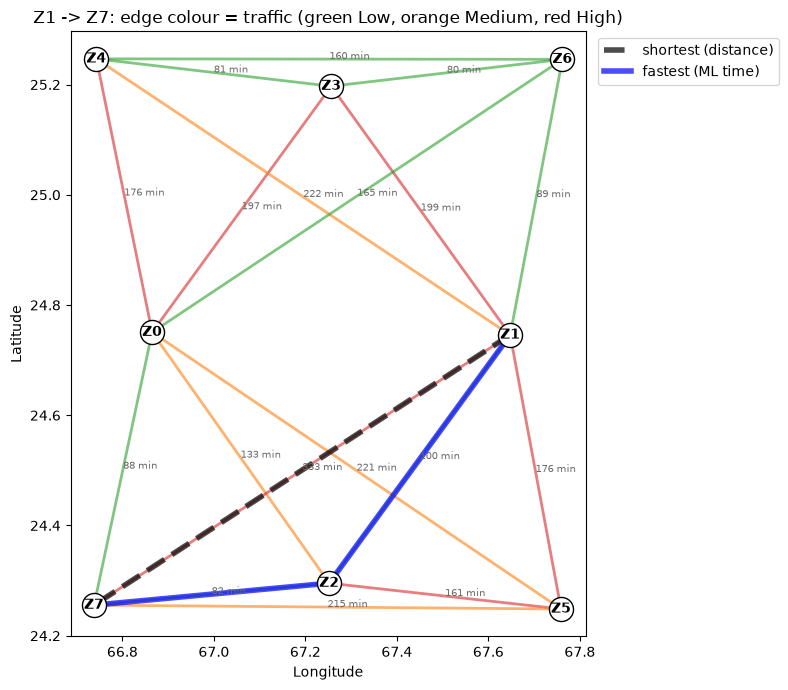

In [31]:
def dijkstra(graph, source, target, weight):
    dist = {v: np.inf for v in graph}; prev = {}
    dist[source] = 0.0
    pq = [(0.0, source)]
    while pq:
        d, u = heapq.heappop(pq)
        if u == target:
            break
        if d > dist[u]:
            continue
        for v, attr in graph[u].items():
            nd = d + attr[weight]
            if nd < dist[v]:
                dist[v], prev[v] = nd, u
                heapq.heappush(pq, (nd, v))
    path, node = [target], target
    while node != source:
        node = prev[node]; path.append(node)
    return path[::-1]

def path_cost(path, key):
    return sum(graph[a][b][key] for a, b in zip(path, path[1:]))

od_rows = []
for s in range(n):
    for t in range(s + 1, n):
        p_short, p_fast = dijkstra(graph, s, t, "dist"), dijkstra(graph, s, t, "time")
        od_rows.append({"source": s, "target": t, "shortest": p_short, "fastest": p_fast,
                        "short_km": path_cost(p_short, "dist"), "short_min": path_cost(p_short, "time"),
                        "fast_km": path_cost(p_fast, "dist"), "fast_min": path_cost(p_fast, "time")})
od = pd.DataFrame(od_rows)
od["differs"] = od["shortest"].astype(str) != od["fastest"].astype(str)
od["time_saved_pct"] = (od["short_min"] - od["fast_min"]) / od["short_min"] * 100
print(f"Origin-destination pairs: {len(od)}")
print(f"Pairs where fastest route != shortest route: {od['differs'].sum()}")
print(f"Average time saved on those pairs: {od.loc[od['differs'], 'time_saved_pct'].mean():.1f}%")

display(od.loc[od["differs"], ["source", "target", "shortest", "fastest", "short_km", "fast_km",
                                "short_min", "fast_min", "time_saved_pct"]].round(1))

# Showcase: prefer a pair where the fastest route is clearly LONGER in km but still quicker
longer_but_faster = od[od["differs"] & (od["fast_km"] > od["short_km"] + 1)]
pool = longer_but_faster if len(longer_but_faster) else od[od["differs"]]
show = od.loc[pool["time_saved_pct"].idxmax()]
SRC, DST = int(show["source"]), int(show["target"])
fmt = lambda p: " -> ".join(f"Z{z}" for z in p)
print(f"\nShowcase trip Z{SRC} -> Z{DST}")
print(f"  Shortest route: {fmt(show['shortest'])}: {show['short_km']:.1f} km, {show['short_min']:.1f} min")
print(f"  Fastest route : {fmt(show['fastest'])}: {show['fast_km']:.1f} km, {show['fast_min']:.1f} min")
results["routing"] = {"n_pairs": len(od), "n_differ": int(od["differs"].sum()),
                      "avg_saving_pct": float(od.loc[od["differs"], "time_saved_pct"].mean()),
                      "src": SRC, "dst": DST, "shortest": list(map(int, show["shortest"])),
                      "fastest": list(map(int, show["fastest"])), "short_km": show["short_km"],
                      "short_min": show["short_min"], "fast_km": show["fast_km"], "fast_min": show["fast_min"]}

tcolor = {"Low": "#2ca02c", "Medium": "#ff7f0e", "High": "#d62728"}
plt.figure(figsize=(8, 7))
for (a, b) in edges:
    e = graph[a][b]
    plt.plot([zone_centres[a, 1], zone_centres[b, 1]], [zone_centres[a, 0], zone_centres[b, 0]],
             color=tcolor[e["traffic"]], lw=2, alpha=0.6)
    plt.text((zone_centres[a, 1] + zone_centres[b, 1]) / 2, (zone_centres[a, 0] + zone_centres[b, 0]) / 2,
             f"{e['time']:.0f} min", fontsize=7, color="dimgray")
for p, style, lab in [(show["shortest"], "k--", "shortest (distance)"), (show["fastest"], "b-", "fastest (ML time)")]:
    plt.plot(zone_centres[p, 1], zone_centres[p, 0], style, lw=4, alpha=0.7, label=lab)
plt.scatter(zone_centres[:, 1], zone_centres[:, 0], s=300, c="white", edgecolors="black", zorder=3)
for i, (la, lo) in enumerate(zone_centres):
    plt.text(lo, la, f"Z{i}", ha="center", va="center", fontsize=10, weight="bold", zorder=4)
plt.title(f"Z{SRC} -> Z{DST}: edge colour = traffic (green Low, orange Medium, red High)")
plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
save_fig("16_route_shortest_vs_fastest"); plt.show()

### 8.3 Reinforcement Learning: Q-Learning Agent

The same routing task as a Markov Decision Process:
* **State** = current zone, **Action** = move to a neighbouring zone.
* **Reward** = −(travel time in minutes) for each move; the episode ends at the destination.
* **Q-learning update:** `Q(s,a) ← Q(s,a) + α [ r + γ · max Q(s', a') − Q(s,a) ]`
* α = 0.1 (learning rate), γ = 1.0 (every minute counts equally; episodes always end), ε-greedy exploration with
  ε = 0.2. Q starts at 0, which is optimistic because every real reward is negative — this encourages exploration.

The agent learns by trial and error with **no map knowledge**, then its greedy route is compared with Dijkstra.

First Q-updates (for hand verification):


,s,a,r,maxQ_next,old,new
0,1,2,-100.217,0.0,0.0,-10.022
1,2,0,-133.209,0.0,0.0,-13.321
2,0,2,-133.209,0.0,0.0,-13.321


Q-learning route : Z1 -> Z2 -> Z7 (182.0 min)
Dijkstra fastest : Z1 -> Z2 -> Z7 (182.0 min)
Same route: True


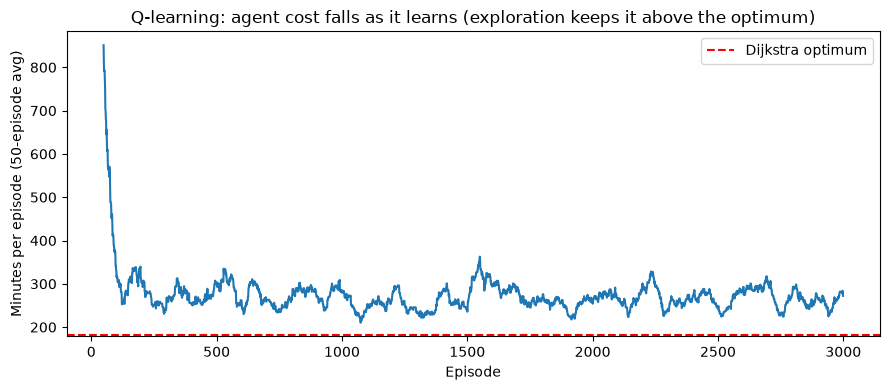

In [32]:
ALPHA, GAMMA, EPSILON, EPISODES, MAX_STEPS = 0.1, 1.0, 0.2, 3000, 30
Q = {s: {a: 0.0 for a in graph[s]} for s in graph}
q_rng = np.random.RandomState(RANDOM_STATE)
episode_cost, first_updates = [], []

for ep in range(EPISODES):
    s, total = SRC, 0.0
    for _ in range(MAX_STEPS):
        acts = list(Q[s])
        a = acts[q_rng.randint(len(acts))] if q_rng.rand() < EPSILON else max(acts, key=Q[s].get)
        r = -graph[s][a]["time"]
        future = 0.0 if a == DST else max(Q[a].values())
        old = Q[s][a]
        Q[s][a] = old + ALPHA * (r + GAMMA * future - old)
        if len(first_updates) < 3:
            first_updates.append({"s": int(s), "a": int(a), "r": r, "maxQ_next": future, "old": old, "new": Q[s][a]})
        total += -r; s = a
        if s == DST:
            break
    episode_cost.append(total)

s, rl_path = SRC, [SRC]
while s != DST and len(rl_path) < 20:
    s = max(Q[s], key=Q[s].get); rl_path.append(s)
print("First Q-updates (for hand verification):")
display(pd.DataFrame(first_updates).round(3))
print("Q-learning route :", fmt(rl_path), f"({path_cost(rl_path, 'time'):.1f} min)")
print("Dijkstra fastest :", fmt(show["fastest"]), f"({show['fast_min']:.1f} min)")
print("Same route:", list(rl_path) == list(show["fastest"]))
results["qlearning"] = {"path": list(map(int, rl_path)), "minutes": path_cost(rl_path, "time"),
                        "matches_dijkstra": list(rl_path) == list(show["fastest"]),
                        "first_updates": first_updates,
                        "start_cost_avg100": float(np.mean(episode_cost[:100])),
                        "end_cost_avg100": float(np.mean(episode_cost[-100:]))}

plt.figure(figsize=(9, 4))
plt.plot(pd.Series(episode_cost).rolling(50).mean())
plt.axhline(show["fast_min"], color="r", ls="--", label="Dijkstra optimum")
plt.xlabel("Episode"); plt.ylabel("Minutes per episode (50-episode avg)")
plt.title("Q-learning: agent cost falls as it learns (exploration keeps it above the optimum)")
plt.legend(); save_fig("17_qlearning_convergence"); plt.show()

## 9. Recommendation System — Best Departure Time

For a *future* trip the traffic level is unknown, but the data gives `P(traffic | hour)`. The expected travel time
for departing at hour h is:

`E[time | h] = Σ over traffic levels  P(traffic | h) × distance ÷ predicted_speed(traffic, weather) × 60`

The recommender ranks departure hours within the user's flexibility window — a **model-based, content-based**
recommender (it uses trip attributes, not other users' ratings).

*Why not collaborative filtering?* Every one of the 50,000 `user_id` values appears exactly once (CE-1), so there is
no history of repeated choices to learn user–user similarity from (the **cold-start** problem).

Trip: 15 km, Rain, wants to leave at 9 AM (+/- 2 h)


,hour,expected_min,vs desired (min)
4,11,29.34,-11.24
0,7,29.47,-11.12
1,8,40.29,-0.30


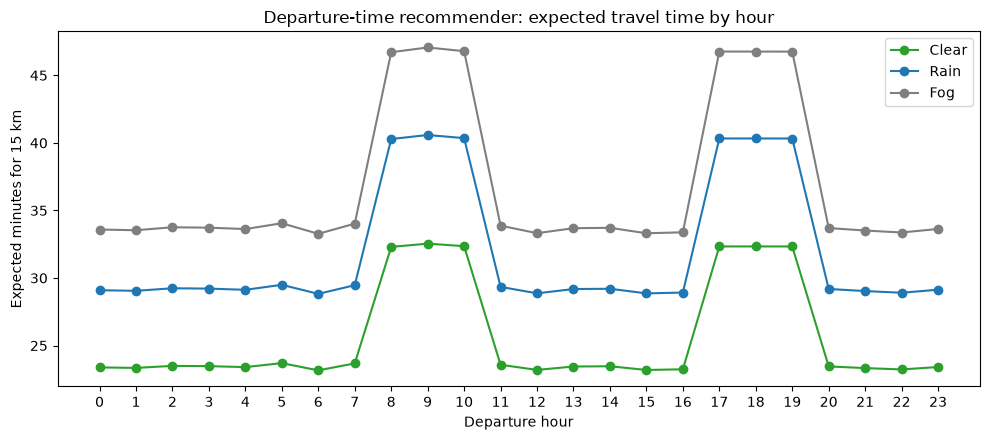

In [33]:
p_traffic_hour = pd.crosstab(df["hour"], df["traffic"], normalize="index")[["Low", "Medium", "High"]]

def expected_minutes(hour, distance_km, weather):
    return sum(p_traffic_hour.loc[hour, t] * distance_km / predict_speed(t, weather) * 60
               for t in ["Low", "Medium", "High"])

def recommend_departure(desired_hour, distance_km, weather, window=2, top=3):
    hours = [(desired_hour + dh) % 24 for dh in range(-window, window + 1)]
    table = pd.DataFrame({"hour": hours, "expected_min": [expected_minutes(h, distance_km, weather) for h in hours]})
    table["vs desired (min)"] = table["expected_min"] - expected_minutes(desired_hour, distance_km, weather)
    return table.sort_values("expected_min").head(top)

print("Trip: 15 km, Rain, wants to leave at 9 AM (+/- 2 h)")
rec = recommend_departure(9, 15, "Rain")
display(rec.round(2))
results["recommender"] = {"example": rec.round(3).to_dict(orient="records"),
                          "p_traffic_hour9": p_traffic_hour.loc[9].round(3).to_dict(),
                          "p_traffic_hour12": p_traffic_hour.loc[12].round(3).to_dict(),
                          "exp_min_9": expected_minutes(9, 15, "Rain"), "exp_min_12": expected_minutes(12, 15, "Rain")}

plt.figure(figsize=(10, 4.5))
for wthr, c in [("Clear", "#2ca02c"), ("Rain", "#1f77b4"), ("Fog", "#7f7f7f")]:
    plt.plot(range(24), [expected_minutes(h, 15, wthr) for h in range(24)], "o-", color=c, label=wthr)
plt.xticks(range(24)); plt.xlabel("Departure hour"); plt.ylabel("Expected minutes for 15 km")
plt.title("Departure-time recommender: expected travel time by hour"); plt.legend()
save_fig("18_departure_recommender"); plt.show()

## 10. Ethical Considerations and Future Trends

**Ethics**
* **Privacy** — GPS start/end points plus timestamps can reveal home and work locations. `user_id` and `trip_id`
  were removed in CE-1; a deployed system should store only aggregated zone-level data and follow data-protection law
  (e.g. India's DPDP Act 2023).
* **Bias and representativeness** — the data covers one region and one month (January 2025) and is synthetic. The model
  must be retrained on real local data before use; seasonal effects (monsoon, festivals) are not represented.
* **Fairness and externalities** — sending all drivers through the "fastest" side streets moves congestion and
  noise into residential areas and school zones. Route costs can include penalties for such roads.
* **Safety** — the fastest route in Fog may not be the safest; safety-weighted costs should be an option.
* **Transparency** — users should see why a route was chosen ("avoids High traffic on Z1–Z4").
* **Environment** — eco-routing can minimise fuel or emissions instead of time.

**Future trends**
* Graph Neural Networks that forecast traffic on the whole road network.
* Real-time streaming data from GPS probes and IoT sensors.
* Multi-agent reinforcement learning for city-wide routing and adaptive traffic signals.
* Federated learning — train on phones without uploading raw location traces.
* Routing for autonomous and connected vehicles that coordinate with each other.

## 11. Save Results and Summary

In [34]:
def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    return o

with open(PROJECT_ROOT / "reports" / "ce2_results.json", "w") as f:
    json.dump(to_jsonable(results), f, indent=2)

summary = pd.DataFrame([
    ["Regression (speed)", "Polynomial deg 2, traffic + weather", f"Test R2 {results['final_reg']['R2']:.4f}, MAE {results['final_reg']['MAE']:.2f} km/h, RMSE {results['final_reg']['RMSE']:.2f} km/h"],
    ["Classification (congestion)", results["final_clf_name"] + " (balanced)", f"Recall {results['final_clf']['recall']:.3f}, F1 {results['final_clf']['f1']:.3f}, Accuracy {results['final_clf']['accuracy']:.3f}"],
    ["Clustering (zones)", f"K-Means k={K_ZONES}", f"Silhouette {results['zone_silhouette']:.3f}"],
    ["Association rules", "Apriori / FP-Growth", f"{results['assoc']['n_itemsets']} frequent itemsets"],
    ["PCA", "16 standardised features", f"{results['pca']['n90']} components for 90% variance"],
    ["Routing", "Dijkstra on ML travel times", f"Fastest != shortest in {results['routing']['n_differ']}/{results['routing']['n_pairs']} pairs"],
    ["Reinforcement learning", "Q-learning", "Matches Dijkstra: " + str(results["qlearning"]["matches_dijkstra"])],
], columns=["Component", "Method", "Result"])
display(summary)
print("Saved:", PROJECT_ROOT / "reports" / "ce2_results.json")
print("Models:", sorted(p.name for p in MODEL_DIR.glob("*.joblib")))

,Component,Method,Result
0,Regression (speed),"Polynomial deg 2, traffic + weather","Test R2 0.5996, MAE 7.22 km/h, RMSE 8.73 km/h"
1,Classification (congestion),Logistic Regression (balanced),"Recall 0.898, F1 0.680, Accuracy 0.785"
2,Clustering (zones),K-Means k=8,Silhouette 0.363
3,Association rules,Apriori / FP-Growth,113 frequent itemsets
4,PCA,16 standardised features,11 components for 90% variance
5,Routing,Dijkstra on ML travel times,Fastest != shortest in 5/28 pairs
6,Reinforcement learning,Q-learning,Matches Dijkstra: True


Saved: /Users/chiragdawra/Desktop/HackSpace/ReRouter/reports/ce2_results.json
Models: ['congestion_classifier.joblib', 'speed_model_poly2.joblib']


## 12. Conclusion

* **Speed model:** a degree-2 polynomial regression on traffic and weather reaches the data's R² ceiling (~0.59).
  The remaining error is natural trip-to-trip variation that no feature in the dataset explains.
* **Congestion classifier:** with class balancing it catches about 9 out of 10 congested trips, trading some
  accuracy for much higher recall — the right trade-off for routing.
* **Unsupervised analysis:** K-Means turns trip locations into routing zones; DBSCAN and PCA show the synthetic data
  has no density hotspots and uncorrelated features.
* **Association rules** confirm the domain picture: `{Fog, High traffic} → {Slow}` with confidence ≈ 0.96.
* **Route optimization:** using ML-predicted travel times, the fastest route differs from the shortest route for
  several origin-destination pairs (Section 8.2), and a Q-learning agent independently learns the same optimal route
  as Dijkstra.
* **Next steps:** real road-network data (OpenStreetMap), live traffic feeds, and retraining on local, multi-season data.